# MetroMove Transit | Exploratory Data Analysis

This notebook looks at 1,000 recorded public transport trips. I first check the quality of the data, clean what I can justify, and then explore trip activity, passengers, fare revenue, journey duration and station-to-station routes.

A few fields turn out to have suspicious patterns. I've kept those limitations visible instead of assuming every recorded value reflects actual operations. `Fare_Amount` is treated as the **total fare collected for a trip**, as defined for this assignment; it isn't a fare per passenger. Currency isn't specified in the data, so I haven't added a currency symbol.

## 1. Initial inspection

I start with the original file, its columns, data types, missing values and duplicate records. This gives me a baseline before I make any changes.

In [56]:
# Libraries for cleaning the data and plotting the results
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno

In [57]:
# Read the original trip file
path = r"files\capstone\Public_Transport_Trips_EDA.xlsx - Sheet1.csv"
df = pd.read_csv(path)

In [58]:
df.head()

,Trip_ID,Mode_of_Transport,Departure_Station,Arrival_Station,Departure_Time,Passenger_Count,Fare_Amount,Trip_Duration_Minutes,Trip_Date,Day_of_Week,Unnamed: 10,Unnamed: 11
0,TRIP0001,FERRY,West End,airport,2024-01-01 06:00:00,21.0,4.343642,26.0,2024-01-01,Sunday,NaN,F
1,TRIP0002,Tram,North Station,Downtown,2024-01-01 06:01:00,46.0,20.673380,134.0,2024-01-01,Saturday,NaN,F
2,TRIP0003,bus,Central,North Station,2024-01-01 06:02:00,91.0,NaN,NaN,2024-01-01,Tuesday,NaN,F
3,TRIP0004,FERRY,Downtown,Central,2024-01-01 06:03:00,27.0,3.767487,NaN,2024-01-01,Sunday,NaN,F
4,TRIP0005,Ferry,Downtown,Central,2024-01-01 06:04:00,66.0,NaN,NaN,2024-01-01,Monday,NaN,F


In [59]:
df.columns

Index(['Trip_ID', 'Mode_of_Transport', 'Departure_Station', 'Arrival_Station',
       'Departure_Time', 'Passenger_Count', 'Fare_Amount',
       'Trip_Duration_Minutes', 'Trip_Date', 'Day_of_Week', 'Unnamed: 10',
       'Unnamed: 11'],
      dtype='str')

In [60]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Trip_ID                1000 non-null   str    
 1   Mode_of_Transport      1000 non-null   str    
 2   Departure_Station      1000 non-null   str    
 3   Arrival_Station        1000 non-null   str    
 4   Departure_Time         1000 non-null   str    
 5   Passenger_Count        900 non-null    float64
 6   Fare_Amount            900 non-null    float64
 7   Trip_Duration_Minutes  900 non-null    float64
 8   Trip_Date              1000 non-null   str    
 9   Day_of_Week            1000 non-null   str    
 10  Unnamed: 10            0 non-null      float64
 11  Unnamed: 11            299 non-null    str    
dtypes: float64(4), str(8)
memory usage: 93.9 KB


### Missing values and possible duplicates

I want to know where information is missing before choosing any replacement values. I'll also check whether whole rows or trip IDs repeat. Those are different checks: two different trips can share other details, but a trip ID should identify a particular record.

In [61]:
# Check the number and percentage of missing values in each column
missing = pd.DataFrame({
    "Missing_Count": df.isna().sum(),
    "Missing_Percent": df.isna().mean() * 100
})

missing

,Missing_Count,Missing_Percent
Trip_ID,0,0.0
Mode_of_Transport,0,0.0
Departure_Station,0,0.0
Arrival_Station,0,0.0
Departure_Time,0,0.0
Passenger_Count,100,10.0
Fare_Amount,100,10.0
Trip_Duration_Minutes,100,10.0
Trip_Date,0,0.0
Day_of_Week,0,0.0


<Figure size 1200x600 with 0 Axes>

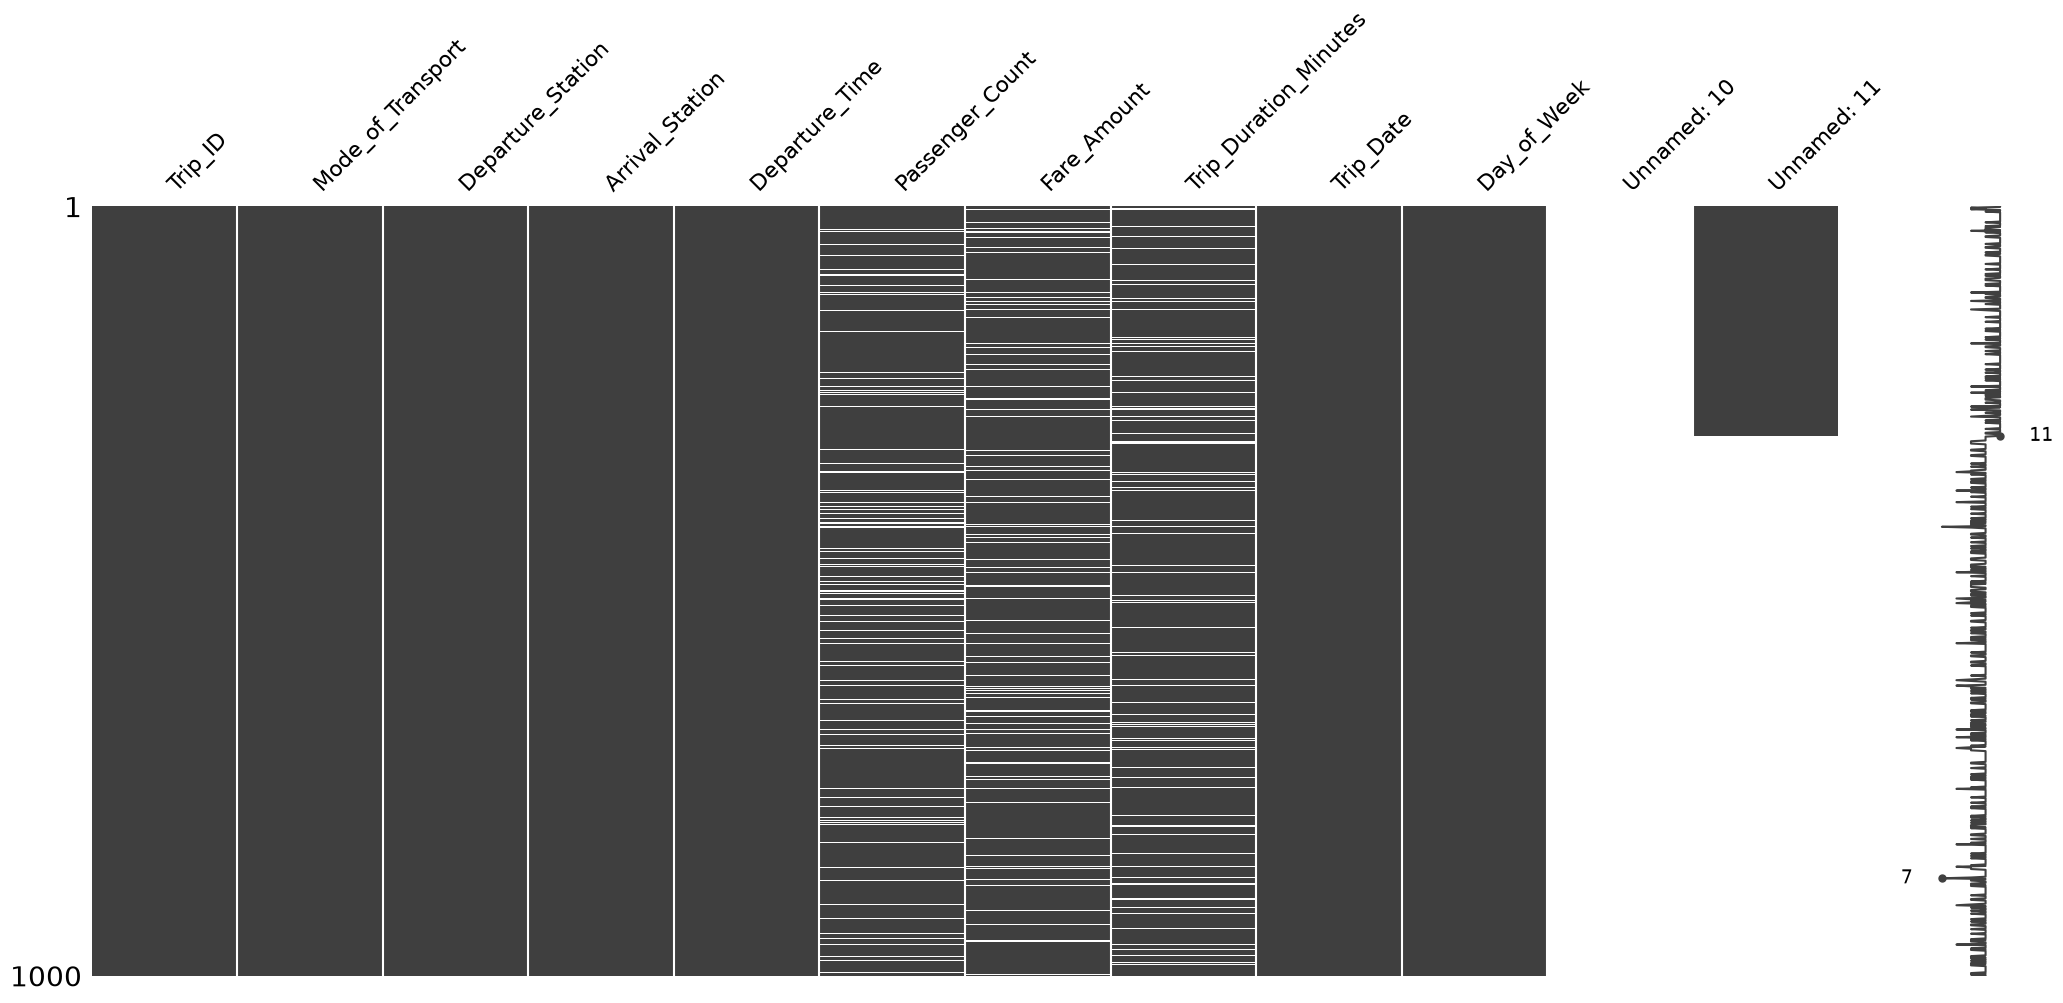

In [62]:
plt.figure(figsize=(12, 6))
msno.matrix(df)
plt.show()

In [63]:
# Check duplicate rows and trip identifiers
print("Duplicate Rows:", df.duplicated().sum())
print("Duplicate Trip IDs:", df["Trip_ID"].duplicated().sum())

Duplicate Rows: 0
Duplicate Trip IDs: 0


### Checking the category labels

I checked the transport modes and station names before cleaning them. At this point I'm looking for labels that refer to the same category but differ in case or spacing.

In [64]:
# Check the original transport mode categories
df["Mode_of_Transport"].value_counts(dropna=False)

Mode_of_Transport
Bus      147
Tram     138
bus      137
train    123
Train    120
FERRY    119
Ferry    118
fErry     50
BUS       48
Name: count, dtype: int64

In [65]:
df["Departure_Station"].value_counts(dropna=False)



Departure_Station
North Station    171
Downtown         167
West End         159
Central          158
Airport          157
South Point      138
 Central          50
Name: count, dtype: int64

In [66]:
df["Arrival_Station"].value_counts(dropna=False)

Arrival_Station
South Point      171
Downtown         168
West End         163
Airport          163
Central          160
North Station    125
airport           50
Name: count, dtype: int64

### First look at the date fields

There are two date-related fields, so I compared them rather than choosing one immediately. The aim is to find out which field, if any, makes sense for analysing activity over time.

In [67]:
# Compare recorded trip dates with dates from departure timestamps
date_check = pd.DataFrame({
    "Trip_Date": pd.to_datetime(df["Trip_Date"]),
    "Departure_Date": pd.to_datetime(df["Departure_Time"]).dt.normalize()
})

date_check["Date_Match"] = (
    date_check["Trip_Date"] == date_check["Departure_Date"]
)

date_check["Date_Match"].value_counts()

Date_Match
False    976
True      24
Name: count, dtype: int64

## 2. Data cleaning and validation

I convert the date fields first so I can compare the dates, extract weekdays and inspect the recorded times. Invalid date strings would become `NaT`, which I check separately rather than silently ignoring.

In [68]:
# Parse both dates; invalid entries would show up as NaT
df["Trip_Date"] = pd.to_datetime(df["Trip_Date"], errors="coerce")
df["Departure_Time"] = pd.to_datetime(df["Departure_Time"], errors="coerce")

# Check the converted types
df[["Trip_Date", "Departure_Time"]].dtypes

Trip_Date         datetime64[us]
Departure_Time    datetime64[us]
dtype: object

In [69]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   Trip_ID                1000 non-null   str           
 1   Mode_of_Transport      1000 non-null   str           
 2   Departure_Station      1000 non-null   str           
 3   Arrival_Station        1000 non-null   str           
 4   Departure_Time         1000 non-null   datetime64[us]
 5   Passenger_Count        900 non-null    float64       
 6   Fare_Amount            900 non-null    float64       
 7   Trip_Duration_Minutes  900 non-null    float64       
 8   Trip_Date              1000 non-null   datetime64[us]
 9   Day_of_Week            1000 non-null   str           
 10  Unnamed: 10            0 non-null      float64       
 11  Unnamed: 11            299 non-null    str           
dtypes: datetime64[us](2), float64(4), str(6)
memory usage: 93.9 KB


In [70]:
# Check for invalid or missing dates after datetime conversion
df[["Trip_Date", "Departure_Time"]].isna().sum()

Trip_Date         0
Departure_Time    0
dtype: int64

In [71]:
# Compare Trip_Date with the date extracted from Departure_Time
df["Date_Match"] = (
    df["Trip_Date"].dt.normalize() == df["Departure_Time"].dt.normalize()
)

# Count matching and mismatching dates
df["Date_Match"].value_counts()

Date_Match
False    976
True      24
Name: count, dtype: int64

In [72]:
# Check records where Trip_Date and Departure_Time do not match
df.loc[
    ~df["Date_Match"],
    ["Trip_ID", "Trip_Date", "Departure_Time", "Day_of_Week"]
].head(10)

,Trip_ID,Trip_Date,Departure_Time,Day_of_Week
24,TRIP0025,2024-01-02,2024-01-01 06:24:00,Tuesday
25,TRIP0026,2024-01-02,2024-01-01 06:25:00,Sunday
26,TRIP0027,2024-01-02,2024-01-01 06:26:00,Tuesday
27,TRIP0028,2024-01-02,2024-01-01 06:27:00,Friday
28,TRIP0029,2024-01-02,2024-01-01 06:28:00,Saturday
29,TRIP0030,2024-01-02,2024-01-01 06:29:00,Saturday
30,TRIP0031,2024-01-02,2024-01-01 06:30:00,Thursday
31,TRIP0032,2024-01-02,2024-01-01 06:31:00,Saturday
32,TRIP0033,2024-01-02,2024-01-01 06:32:00,Wednesday
33,TRIP0034,2024-01-02,2024-01-01 06:33:00,Friday


In [73]:
# Calculate the difference in days between Trip_Date and Departure_Time
df["Date_Difference"] = (
    df["Trip_Date"].dt.normalize() -
    df["Departure_Time"].dt.normalize()
).dt.days

# Check how frequently each difference occurs
df["Date_Difference"].value_counts().sort_index()

Date_Difference
0     24
1     24
2     24
3     24
4     24
5     24
6     24
7     24
8     24
9     24
10    24
11    24
12    24
13    24
14    24
15    24
16    24
17    24
18    24
19    24
20    24
21    24
22    24
23    24
24    24
25    24
26    24
27    24
28    24
29    24
30    24
31    24
32    24
33    24
34    24
35    24
36    24
37    24
38    24
39    24
40    24
41    16
Name: count, dtype: int64

### What the date checks show

Only **24 of 1,000** trip dates match the date attached to `Departure_Time`; the other **976** do not. `Departure_Time` assigns every record to **1 January 2024**, while `Trip_Date` covers **42 dates from 1 January to 11 February 2024**. Most of those dates have exactly 24 trips, with just 16 on the last date.

I use `Trip_Date` as a **provisional** date for the later charts because it provides a usable sequence. That does not prove those dates are genuine. I also inspect the clock times to decide whether any peak-hour analysis would be defensible.

In [74]:
# Check the distribution of dates in Departure_Time
df["Departure_Time"].dt.date.value_counts().sort_index()

Departure_Time
2024-01-01    1000
Name: count, dtype: int64

In [75]:
# Check the date range and distribution of trips in Trip_Date
print("Earliest Trip Date:", df["Trip_Date"].min())
print("Latest Trip Date:", df["Trip_Date"].max())
print("Number of Unique Dates:", df["Trip_Date"].nunique())

df["Trip_Date"].value_counts().sort_index()

Earliest Trip Date: 2024-01-01 00:00:00
Latest Trip Date: 2024-02-11 00:00:00
Number of Unique Dates: 42


Trip_Date
2024-01-01    24
2024-01-02    24
2024-01-03    24
2024-01-04    24
2024-01-05    24
2024-01-06    24
2024-01-07    24
2024-01-08    24
2024-01-09    24
2024-01-10    24
2024-01-11    24
2024-01-12    24
2024-01-13    24
2024-01-14    24
2024-01-15    24
2024-01-16    24
2024-01-17    24
2024-01-18    24
2024-01-19    24
2024-01-20    24
2024-01-21    24
2024-01-22    24
2024-01-23    24
2024-01-24    24
2024-01-25    24
2024-01-26    24
2024-01-27    24
2024-01-28    24
2024-01-29    24
2024-01-30    24
2024-01-31    24
2024-02-01    24
2024-02-02    24
2024-02-03    24
2024-02-04    24
2024-02-05    24
2024-02-06    24
2024-02-07    24
2024-02-08    24
2024-02-09    24
2024-02-10    24
2024-02-11    16
Name: count, dtype: int64

In [76]:
# Check the distribution of trips by departure hour
df["Departure_Time"].dt.hour.value_counts().sort_index()

Departure_Time
6     60
7     60
8     60
9     60
10    60
11    60
12    60
13    60
14    60
15    60
16    60
17    60
18    60
19    60
20    60
21    60
22    40
Name: count, dtype: int64

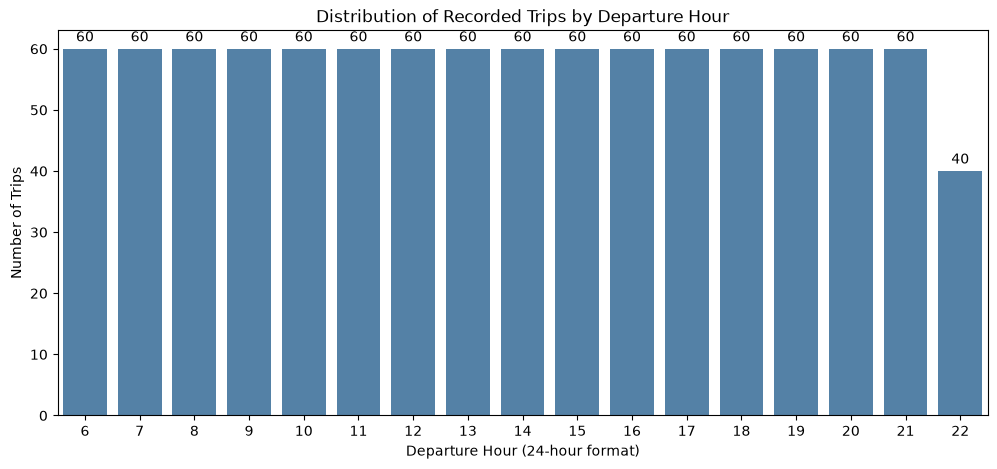

In [77]:
# Plot the distribution of trips by departure hour
plt.figure(figsize=(12, 5))

hourly_trips = df["Departure_Time"].dt.hour.value_counts().sort_index()

ax = sns.barplot(
    x=hourly_trips.index,
    y=hourly_trips.values,
    color="steelblue"
)

ax.bar_label(ax.containers[0], padding=3)

plt.title("Distribution of Recorded Trips by Departure Hour")
plt.xlabel("Departure Hour (24-hour format)")
plt.ylabel("Number of Trips")
plt.show()

In [78]:
# Check the time intervals between consecutive recorded trips
df["Departure_Time"].diff().value_counts()

Departure_Time
0 days 00:01:00    999
Name: count, dtype: int64

### Weekday check

The departure timestamps move forward by exactly **one minute** between consecutive records. That makes them unsuitable for identifying real peak travel hours. I also found that **850 original weekday labels** disagree with the weekday calculated from `Trip_Date`.

I rebuild `Day_of_Week` from `Trip_Date`, while keeping the uncertainty about the underlying dates in mind.

In [79]:
# Compare recorded weekdays with weekdays derived from Trip_Date
df["Weekday_Match"] = (
    df["Day_of_Week"].str.strip().str.lower() == df["Trip_Date"].dt.day_name().str.lower()
)

# Count matching and mismatching weekday records
df["Weekday_Match"].value_counts()

Weekday_Match
False    850
True     150
Name: count, dtype: int64

In [80]:
# Recalculate Day_of_Week using Trip_Date
df["Day_of_Week"] = df["Trip_Date"].dt.day_name()

# Check the corrected weekday values
df[["Trip_Date", "Day_of_Week"]].head(10)

,Trip_Date,Day_of_Week
0,2024-01-01,Monday
1,2024-01-01,Monday
2,2024-01-01,Monday
3,2024-01-01,Monday
4,2024-01-01,Monday
5,2024-01-01,Monday
6,2024-01-01,Monday
7,2024-01-01,Monday
8,2024-01-01,Monday
9,2024-01-01,Monday


In [81]:
# Check one weekday against the corrected date column
df[df["Day_of_Week"] == "Tuesday"]

,Trip_ID,Mode_of_Transport,Departure_Station,Arrival_Station,Departure_Time,Passenger_Count,Fare_Amount,Trip_Duration_Minutes,Trip_Date,Day_of_Week,Unnamed: 10,Unnamed: 11,Date_Match,Date_Difference,Weekday_Match
24,TRIP0025,bus,North Station,West End,2024-01-01 06:24:00,56.0,20.552583,22.0,2024-01-02,Tuesday,NaN,F,False,1,True
25,TRIP0026,Bus,Airport,North Station,2024-01-01 06:25:00,83.0,45.352495,119.0,2024-01-02,Tuesday,NaN,F,False,1,False
26,TRIP0027,Tram,South Point,South Point,2024-01-01 06:26:00,58.0,16.414037,NaN,2024-01-02,Tuesday,NaN,T,False,1,True
27,TRIP0028,Train,South Point,Airport,2024-01-01 06:27:00,4.0,24.083631,149.0,2024-01-02,Tuesday,NaN,F,False,1,False
28,TRIP0029,train,Central,Central,2024-01-01 06:28:00,NaN,11.688435,147.0,2024-01-02,Tuesday,NaN,T,False,1,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
883,TRIP0884,bus,Airport,Downtown,2024-01-01 20:43:00,91.0,29.553357,175.0,2024-02-06,Tuesday,NaN,NaN,False,36,True
884,TRIP0885,FERRY,South Point,Airport,2024-01-01 20:44:00,98.0,29.257044,23.0,2024-02-06,Tuesday,NaN,NaN,False,36,False
885,TRIP0886,Bus,Downtown,Airport,2024-01-01 20:45:00,11.0,49.538618,138.0,2024-02-06,Tuesday,NaN,NaN,False,36,False
886,TRIP0887,Train,North Station,West End,2024-01-01 20:46:00,54.0,37.958143,178.0,2024-02-06,Tuesday,NaN,NaN,False,36,False


### Cleaning transport modes and station names

Different spellings and extra spaces would split what should be the same category into separate groups. I standardise the labels and check the counts again before using them in charts.

In [82]:
# Check transport modes and their frequencies
df["Mode_of_Transport"].value_counts(dropna=False)

Mode_of_Transport
Bus      147
Tram     138
bus      137
train    123
Train    120
FERRY    119
Ferry    118
fErry     50
BUS       48
Name: count, dtype: int64

In [83]:
# Standardise transport modes by removing whitespace and correcting capitalization
df["Mode_of_Transport"] = df["Mode_of_Transport"].str.strip().str.title()

# Check the cleaned categories
df["Mode_of_Transport"].value_counts(dropna=False)

Mode_of_Transport
Bus      332
Ferry    287
Train    243
Tram     138
Name: count, dtype: int64

In [84]:
# Check departure station names and their frequencies
df["Departure_Station"].value_counts(dropna=False)

Departure_Station
North Station    171
Downtown         167
West End         159
Central          158
Airport          157
South Point      138
 Central          50
Name: count, dtype: int64

In [85]:
# Standardise departure station names by removing extra whitespace and correcting capitalization
df["Departure_Station"] = df["Departure_Station"].str.strip().str.title()

# Check the cleaned station names
df["Departure_Station"].value_counts(dropna=False)

Departure_Station
Central          208
North Station    171
Downtown         167
West End         159
Airport          157
South Point      138
Name: count, dtype: int64

In [86]:
# Check arrival station names and their frequencies
df["Arrival_Station"].value_counts(dropna=False)

Arrival_Station
South Point      171
Downtown         168
West End         163
Airport          163
Central          160
North Station    125
airport           50
Name: count, dtype: int64

In [87]:
# Standardise arrival station names by removing whitespace and correcting capitalization
df["Arrival_Station"] = df["Arrival_Station"].str.strip().str.title()

# Check the cleaned arrival station names
df["Arrival_Station"].value_counts(dropna=False)

Arrival_Station
Airport          213
South Point      171
Downtown         168
West End         163
Central          160
North Station    125
Name: count, dtype: int64

### Passenger counts: checks and missing values

I checked the available passenger counts for zeros and negatives, then looked at their distribution. The observed range is **1 to 99** passengers. For the missing entries, I compare transport modes before choosing a replacement; a single overall figure could ignore differences between services.

In [88]:
# Check for zero or negative passenger counts
print("Zero passengers:", (df["Passenger_Count"] == 0).sum())
print("Negative passengers:", (df["Passenger_Count"] < 0).sum())

# Check the minimum and maximum passenger counts
df["Passenger_Count"].agg(["min", "max"])

Zero passengers: 0
Negative passengers: 0


min     1.0
max    99.0
Name: Passenger_Count, dtype: float64

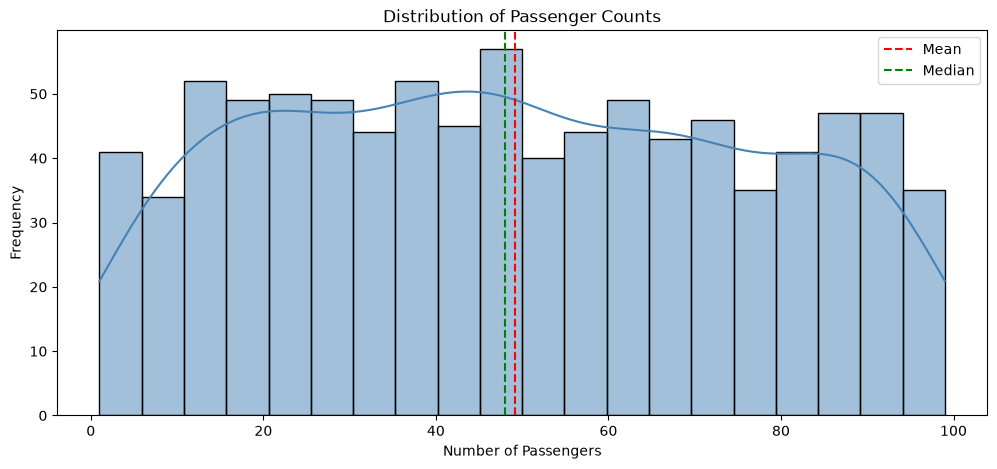

In [89]:
# Check passenger count distribution before filling gaps
fig, ax = plt.subplots(figsize=(12, 5))

sns.histplot(
    data=df,
    x="Passenger_Count",
    bins=20,
    kde=True,
    color="steelblue",
    ax=ax
)

ax.axvline(df["Passenger_Count"].mean(), color="red",
           linestyle="--", label="Mean")

ax.axvline(df["Passenger_Count"].median(), color="green",
           linestyle="--", label="Median")

ax.set_title("Distribution of Passenger Counts")
ax.set_xlabel("Number of Passengers")
ax.set_ylabel("Frequency")
ax.legend()

plt.show()

In [90]:
# Check missing passenger counts across transport modes
df.groupby("Mode_of_Transport")["Passenger_Count"].agg(
    Total_Trips="size",
    Missing_Count=lambda x: x.isna().sum(),
    Missing_Percent=lambda x: round(x.isna().mean() * 100, 2),
    Median_Passengers="median"
)

,Total_Trips,Missing_Count,Missing_Percent,Median_Passengers
Mode_of_Transport,,,,
Bus,332,28,8.43,48.0
Ferry,287,25,8.71,48.0
Train,243,33,13.58,45.5
Tram,138,14,10.14,49.0


I fill missing passenger counts with the **median within each transport mode** and keep a flag showing which values were estimated. Train's median is **45.5**, so I round the imputed counts to whole people. The replacement is only an estimate, not an actual recorded headcount.

In [91]:
# Mark rows with missing passenger counts
df["Passenger_Count_Imputed"] = df["Passenger_Count"].isna()

# Fill missing passenger counts using the median for each transport mode
df["Passenger_Count"] = df["Passenger_Count"].fillna(
    df.groupby("Mode_of_Transport")["Passenger_Count"].transform("median")
)

# Check that missing values have been handled
df["Passenger_Count"].isna().sum()

np.int64(0)

In [92]:
# Check passenger counts that were filled after median imputation
df.loc[
    df["Passenger_Count_Imputed"],
    ["Mode_of_Transport", "Passenger_Count"]
].groupby("Mode_of_Transport")["Passenger_Count"].agg(
    ["count", "min", "max"]
)

,count,min,max
Mode_of_Transport,,,
Bus,28,48.0,48.0
Ferry,25,48.0,48.0
Train,33,45.5,45.5
Tram,14,49.0,49.0


In [93]:
# Round only the imputed passenger counts to whole numbers
df.loc[df["Passenger_Count_Imputed"], "Passenger_Count"] = (
    df.loc[df["Passenger_Count_Imputed"], "Passenger_Count"]
    .round()
    .astype(int)
)

# Check the updated values
df.loc[
    df["Passenger_Count_Imputed"]
].groupby("Mode_of_Transport")["Passenger_Count"].unique()

Mode_of_Transport
Bus      [48.0]
Ferry    [48.0]
Train    [46.0]
Tram     [49.0]
Name: Passenger_Count, dtype: object

### Fare revenue: checks and missing values

`Fare_Amount` is the amount collected for a trip, not the cost of a single ticket. I found no zero or negative non-missing fares. The mean and median are close, but I still check whether passenger count or transport mode gives a better basis for estimating missing values.

In [94]:
# Check for zero or negative fare amounts
print("Zero fares:", (df["Fare_Amount"] == 0).sum())
print("Negative fares:", (df["Fare_Amount"] < 0).sum())

# Check the minimum, maximum, mean and median fare amounts
df["Fare_Amount"].agg(["min", "max", "mean", "median"])

Zero fares: 0
Negative fares: 0


min        0.500576
max       49.945184
mean      25.360742
median    25.403856
Name: Fare_Amount, dtype: float64

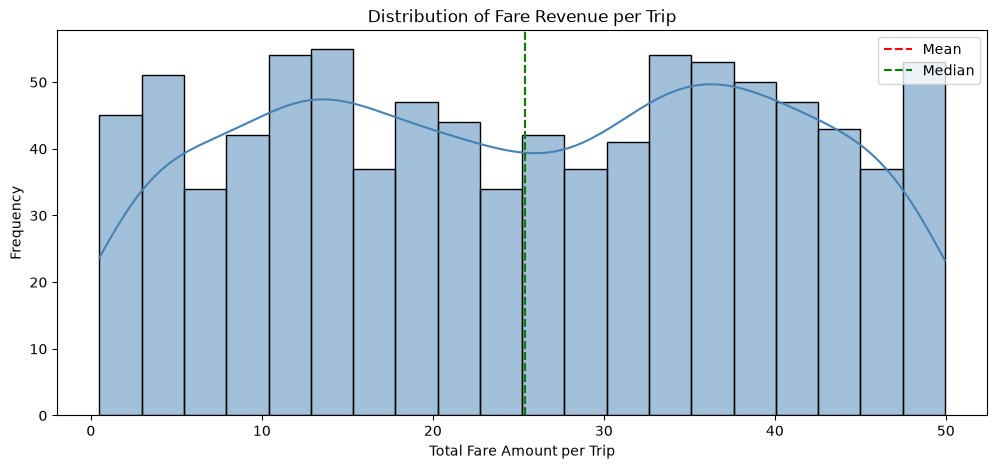

In [95]:
# Check the distribution of total fare revenue per trip
fig, ax = plt.subplots(figsize=(12, 5))

sns.histplot(
    data=df,
    x="Fare_Amount",
    bins=20,
    kde=True,
    color="steelblue",
    ax=ax
)

ax.axvline(df["Fare_Amount"].mean(), color="red",
           linestyle="--", label="Mean")

ax.axvline(df["Fare_Amount"].median(), color="green",
           linestyle="--", label="Median")

ax.set_title("Distribution of Fare Revenue per Trip")
ax.set_xlabel("Total Fare Amount per Trip")
ax.set_ylabel("Frequency")
ax.legend()

plt.show()

In [96]:
# Check missing fare amounts and typical fares across transport modes
df.groupby("Mode_of_Transport")["Fare_Amount"].agg(
    Total_Trips="size",
    Missing_Count=lambda x: x.isna().sum(),
    Missing_Percent=lambda x: round(x.isna().mean() * 100, 2),
    Mean_Fare="mean",
    Median_Fare="median"
).round(2)

,Total_Trips,Missing_Count,Missing_Percent,Mean_Fare,Median_Fare
Mode_of_Transport,,,,,
Bus,332,33,9.94,25.62,26.31
Ferry,287,25,8.71,24.39,23.55
Train,243,30,12.35,26.26,26.62
Tram,138,12,8.70,25.24,25.29


I compare passenger count with fare revenue before filling the missing fares. The overall scatter plot shows little linear relationship. I also check the relationship within each transport mode, since combining services could otherwise hide a pattern.

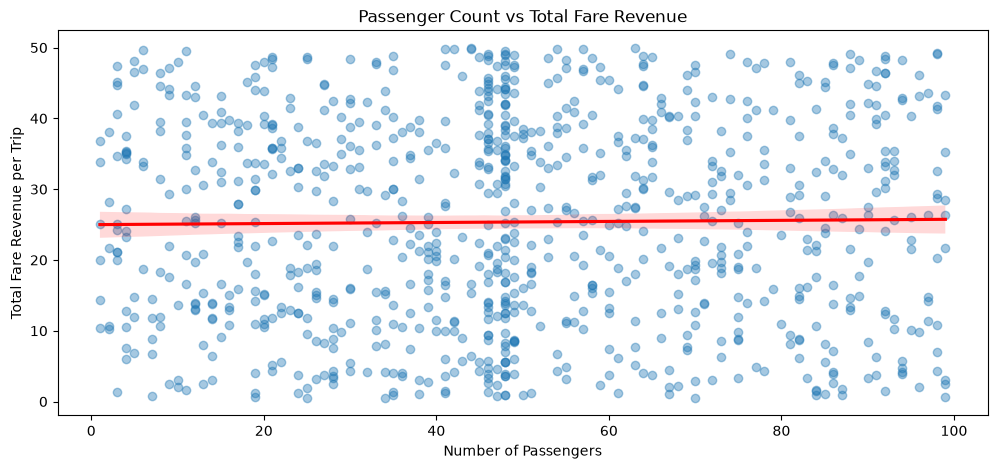

In [97]:
# Check the relationship between passenger count and fare revenue
fig, ax = plt.subplots(figsize=(12, 5))

sns.regplot(
    data=df,
    x="Passenger_Count",
    y="Fare_Amount",
    scatter_kws={"alpha": 0.4},
    line_kws={"color": "red"},
    ax=ax
)

ax.set_title("Passenger Count vs Total Fare Revenue")
ax.set_xlabel("Number of Passengers")
ax.set_ylabel("Total Fare Revenue per Trip")

plt.show()

I use the **median fare amount within each transport mode** for missing fares and keep an imputation flag. This is a simple, traceable estimate. It should not be reported as money that was definitely collected.

In [98]:
# Mark rows with missing fare amounts
df["Fare_Amount_Imputed"] = df["Fare_Amount"].isna()

# Fill missing fares using the median fare for each transport mode
df["Fare_Amount"] = df["Fare_Amount"].fillna(
    df.groupby("Mode_of_Transport")["Fare_Amount"].transform("median")
)

# Check remaining missing values
df["Fare_Amount"].isna().sum()

np.int64(0)

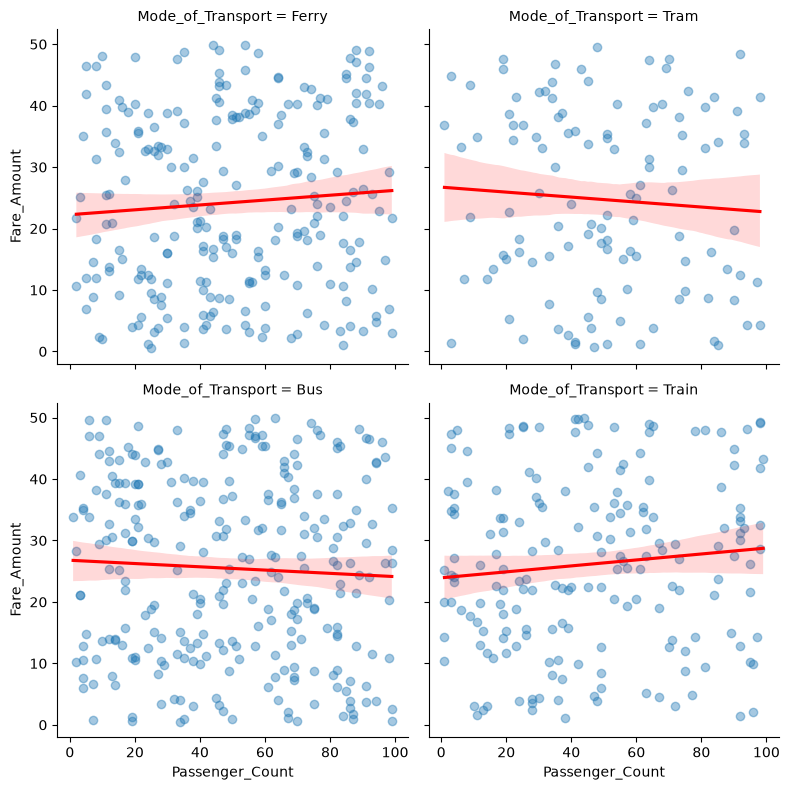

In [99]:
# Check passenger count vs fare revenue separately by transport mode
sns.lmplot(
    data=df.loc[~df["Fare_Amount_Imputed"] & ~df["Passenger_Count_Imputed"]],
    x="Passenger_Count",
    y="Fare_Amount",
    col="Mode_of_Transport",
    col_wrap=2,
    height=4,
    scatter_kws={"alpha": 0.4},
    line_kws={"color": "red"}
)

plt.show()

### Trip durations: checks and missing values

I check for impossible durations and look at the overall distribution before filling gaps. The non-missing durations run from **5 to 179 minutes**. Longer journeys are not automatically errors; they may just be different routes.

In [100]:
# Check for zero or negative trip durations
print("Zero durations:", (df["Trip_Duration_Minutes"] == 0).sum())
print("Negative durations:", (df["Trip_Duration_Minutes"] < 0).sum())

# Check the minimum, maximum, mean and median trip durations
df["Trip_Duration_Minutes"].agg(["min", "max", "mean", "median"])

Zero durations: 0
Negative durations: 0


min         5.00
max       179.00
mean       94.27
median     97.50
Name: Trip_Duration_Minutes, dtype: float64

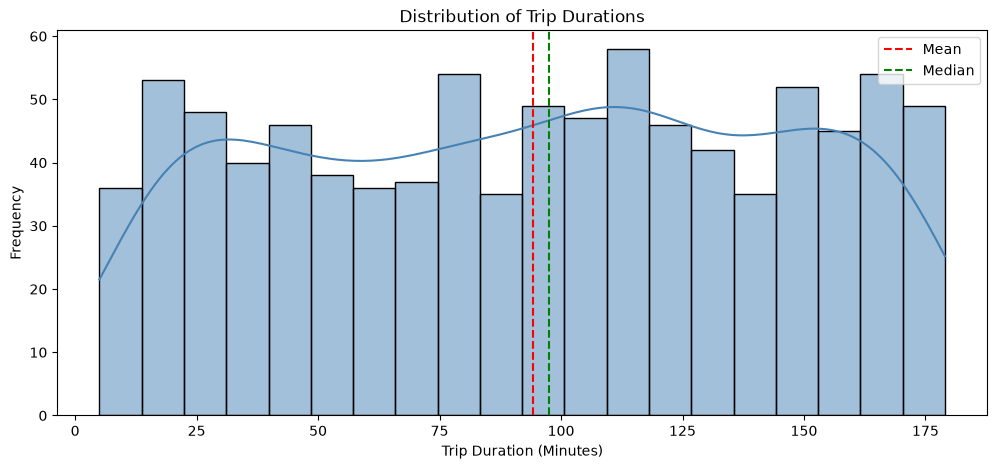

In [101]:
# Check trip duration distribution before filling gaps
fig, ax = plt.subplots(figsize=(12, 5))

sns.histplot(
    data=df,
    x="Trip_Duration_Minutes",
    bins=20,
    kde=True,
    color="steelblue",
    ax=ax
)

ax.axvline(df["Trip_Duration_Minutes"].mean(),
           color="red", linestyle="--", label="Mean")

ax.axvline(df["Trip_Duration_Minutes"].median(),
           color="green", linestyle="--", label="Median")

ax.set_title("Distribution of Trip Durations")
ax.set_xlabel("Trip Duration (Minutes)")
ax.set_ylabel("Frequency")
ax.legend()

plt.show()

In [102]:
# Check missing trip durations and typical durations across transport modes
df.groupby("Mode_of_Transport")["Trip_Duration_Minutes"].agg(
    Total_Trips="size",
    Missing_Count=lambda x: x.isna().sum(),
    Missing_Percent=lambda x: round(x.isna().mean() * 100, 2),
    Mean_Duration="mean",
    Median_Duration="median"
).round(2)

,Total_Trips,Missing_Count,Missing_Percent,Mean_Duration,Median_Duration
Mode_of_Transport,,,,,
Bus,332,33,9.94,96.21,100.0
Ferry,287,26,9.06,91.59,93.0
Train,243,24,9.88,94.37,99.0
Tram,138,17,12.32,95.07,94.0


The duration medians vary a little between modes. I use each mode's median for missing durations and keep a separate flag. Route distance would probably be helpful here, but the dataset does not include it.

In [103]:
# Mark rows with missing trip durations
df["Trip_Duration_Imputed"] = df["Trip_Duration_Minutes"].isna()

# Fill missing durations using the median for each transport mode
df["Trip_Duration_Minutes"] = df["Trip_Duration_Minutes"].fillna(
    df.groupby("Mode_of_Transport")["Trip_Duration_Minutes"].transform("median")
)

# Check that no missing trip durations remain
df["Trip_Duration_Minutes"].isna().sum()

np.int64(0)

### Removing unclear fields and checking the cleaned data

After filling the three numerical columns, I check the full dataset for remaining missing values. Two unnamed columns need a separate look: one is entirely blank, while the other has `F` and `T` values with no explanation in the data dictionary. I exclude them rather than guessing what they mean.

I also remove the temporary date-check columns and the incorrect `Day_of_week` field. I keep `Day_of_Week`, which I recalculated from `Trip_Date`, along with the three imputation flags.

In [104]:
# See whether any columns still have missing values
df.isna().sum()

Trip_ID                       0
Mode_of_Transport             0
Departure_Station             0
Arrival_Station               0
Departure_Time                0
Passenger_Count               0
Fare_Amount                   0
Trip_Duration_Minutes         0
Trip_Date                     0
Day_of_Week                   0
Unnamed: 10                1000
Unnamed: 11                 701
Date_Match                    0
Date_Difference               0
Weekday_Match                 0
Passenger_Count_Imputed       0
Fare_Amount_Imputed           0
Trip_Duration_Imputed         0
dtype: int64

In [105]:
# Check the contents of the unnamed columns
df[["Unnamed: 10", "Unnamed: 11"]].describe(include="all")

,Unnamed: 10,Unnamed: 11
count,0.0,299
unique,NaN,2
top,NaN,F
freq,NaN,250
mean,NaN,NaN
std,NaN,NaN
min,NaN,NaN
25%,NaN,NaN
50%,NaN,NaN
75%,NaN,NaN


In [106]:
# Check the values and associated records in Unnamed: 11
print(df["Unnamed: 11"].value_counts(dropna=False))

df.loc[
    df["Unnamed: 11"].notna(),
    ["Trip_ID", "Mode_of_Transport", "Unnamed: 11"]
].head(15)

Unnamed: 11
NaN    701
F      250
T       49
Name: count, dtype: int64


,Trip_ID,Mode_of_Transport,Unnamed: 11
0,TRIP0001,Ferry,F
1,TRIP0002,Tram,F
2,TRIP0003,Bus,F
3,TRIP0004,Ferry,F
4,TRIP0005,Ferry,F
5,TRIP0006,Ferry,T
6,TRIP0007,Bus,T
7,TRIP0008,Ferry,F
8,TRIP0009,Train,F
9,TRIP0010,Ferry,F


In [107]:
# Drop unnamed columns that are empty or have no documented business meaning
df.drop(columns=["Unnamed: 10", "Unnamed: 11"], inplace=True)

# Check the remaining columns
df.columns.tolist()

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_304\733480399.py:2: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=["Unnamed: 10", "Unnamed: 11"], inplace=True)


['Trip_ID',
 'Mode_of_Transport',
 'Departure_Station',
 'Arrival_Station',
 'Departure_Time',
 'Passenger_Count',
 'Fare_Amount',
 'Trip_Duration_Minutes',
 'Trip_Date',
 'Day_of_Week',
 'Date_Match',
 'Date_Difference',
 'Weekday_Match',
 'Passenger_Count_Imputed',
 'Fare_Amount_Imputed',
 'Trip_Duration_Imputed']

In [108]:
df.head(5)

,Trip_ID,Mode_of_Transport,Departure_Station,Arrival_Station,Departure_Time,Passenger_Count,Fare_Amount,Trip_Duration_Minutes,Trip_Date,Day_of_Week,Date_Match,Date_Difference,Weekday_Match,Passenger_Count_Imputed,Fare_Amount_Imputed,Trip_Duration_Imputed
0,TRIP0001,Ferry,West End,Airport,2024-01-01 06:00:00,21.0,4.343642,26.0,2024-01-01,Monday,True,0,False,False,False,False
1,TRIP0002,Tram,North Station,Downtown,2024-01-01 06:01:00,46.0,20.673380,134.0,2024-01-01,Monday,True,0,False,False,False,False
2,TRIP0003,Bus,Central,North Station,2024-01-01 06:02:00,91.0,26.312252,100.0,2024-01-01,Monday,True,0,False,False,True,True
3,TRIP0004,Ferry,Downtown,Central,2024-01-01 06:03:00,27.0,3.767487,93.0,2024-01-01,Monday,True,0,False,False,False,True
4,TRIP0005,Ferry,Downtown,Central,2024-01-01 06:04:00,66.0,23.550152,93.0,2024-01-01,Monday,True,0,True,False,True,True


In [109]:
# Keep the corrected weekday and remove temporary validation columns
df = df.drop(
    columns=[
        "Day_of_week",
        "Date_Match",
        "Date_Difference",
        "Weekday_Match"
    ],
    errors="ignore"
)

# Check the corrected weekday values
df[["Trip_Date", "Day_of_Week"]].head(10)

,Trip_Date,Day_of_Week
0,2024-01-01,Monday
1,2024-01-01,Monday
2,2024-01-01,Monday
3,2024-01-01,Monday
4,2024-01-01,Monday
5,2024-01-01,Monday
6,2024-01-01,Monday
7,2024-01-01,Monday
8,2024-01-01,Monday
9,2024-01-01,Monday


In [110]:
# Final data quality check after cleaning
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   Trip_ID                  1000 non-null   str           
 1   Mode_of_Transport        1000 non-null   str           
 2   Departure_Station        1000 non-null   str           
 3   Arrival_Station          1000 non-null   str           
 4   Departure_Time           1000 non-null   datetime64[us]
 5   Passenger_Count          1000 non-null   float64       
 6   Fare_Amount              1000 non-null   float64       
 7   Trip_Duration_Minutes    1000 non-null   float64       
 8   Trip_Date                1000 non-null   datetime64[us]
 9   Day_of_Week              1000 non-null   str           
 10  Passenger_Count_Imputed  1000 non-null   bool          
 11  Fare_Amount_Imputed      1000 non-null   bool          
 12  Trip_Duration_Imputed    1000 non-null   bool 

In [111]:
# Passenger counts should be whole numbers
df["Passenger_Count"] = df["Passenger_Count"].astype(int)
df["Passenger_Count"].dtype

dtype('int64')

In [112]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   Trip_ID                  1000 non-null   str           
 1   Mode_of_Transport        1000 non-null   str           
 2   Departure_Station        1000 non-null   str           
 3   Arrival_Station          1000 non-null   str           
 4   Departure_Time           1000 non-null   datetime64[us]
 5   Passenger_Count          1000 non-null   int64         
 6   Fare_Amount              1000 non-null   float64       
 7   Trip_Duration_Minutes    1000 non-null   float64       
 8   Trip_Date                1000 non-null   datetime64[us]
 9   Day_of_Week              1000 non-null   str           
 10  Passenger_Count_Imputed  1000 non-null   bool          
 11  Fare_Amount_Imputed      1000 non-null   bool          
 12  Trip_Duration_Imputed    1000 non-null   bool 

## 3. Descriptive statistics

Before looking at individual charts, I review the typical values, spread and most common categories. The numerical summaries now include imputed values, so they describe the **cleaned working data**, not only the original observations.

The average trip has about **49 passengers**, **25.38** in fare revenue and a duration of about **94.5 minutes**. The category summary gives a quick check that I am working with four modes and six stations.

In [113]:
# Get descriptive statistics for the main numerical variables
df[[
    "Passenger_Count",
    "Fare_Amount",
    "Trip_Duration_Minutes"
]].describe().round(2)

,Passenger_Count,Fare_Amount,Trip_Duration_Minutes
count,1000.00,1000.00,1000.00
mean,48.99,25.38,94.54
std,26.28,13.73,48.05
min,1.00,0.50,5.00
25%,28.00,13.92,55.00
50%,48.00,26.17,99.00
75%,70.00,36.58,132.25
max,99.00,49.95,179.00


In [114]:
# Get descriptive statistics for categorical variables
df[[
    "Mode_of_Transport",
    "Departure_Station",
    "Arrival_Station",
    "Day_of_Week"
]].describe()

,Mode_of_Transport,Departure_Station,Arrival_Station,Day_of_Week
count,1000,1000,1000,1000
unique,4,6,6,7
top,Bus,Central,Airport,Monday
freq,332,208,213,144


## 4. Univariate analysis

Here I look at one field at a time. The counts tell me how recorded trips are divided between modes, stations and weekdays. Boxplots then show the spread of passenger counts, fares and durations without repeating the histograms from cleaning.

I treat weekday results cautiously: the dates are highly regular, so the trip counts alone should not be presented as genuine weekday demand.

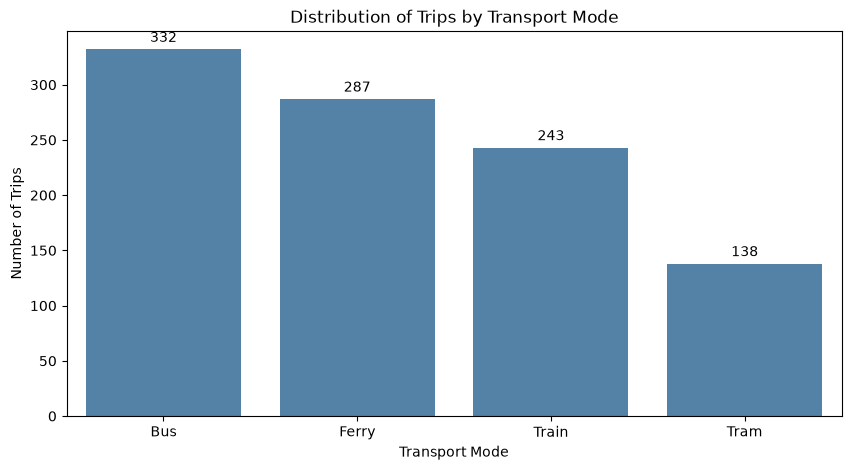

In [115]:
# Plot the distribution of trips by transport mode
fig, ax = plt.subplots(figsize=(10, 5))

sns.countplot(
    data=df,
    x="Mode_of_Transport",
    order=df["Mode_of_Transport"].value_counts().index,
    color="steelblue",
    ax=ax
)

# Show the trip totals above each bar
for container in ax.containers:
    ax.bar_label(container, padding=3)

ax.set_title("Distribution of Trips by Transport Mode")
ax.set_xlabel("Transport Mode")
ax.set_ylabel("Number of Trips")

plt.show()

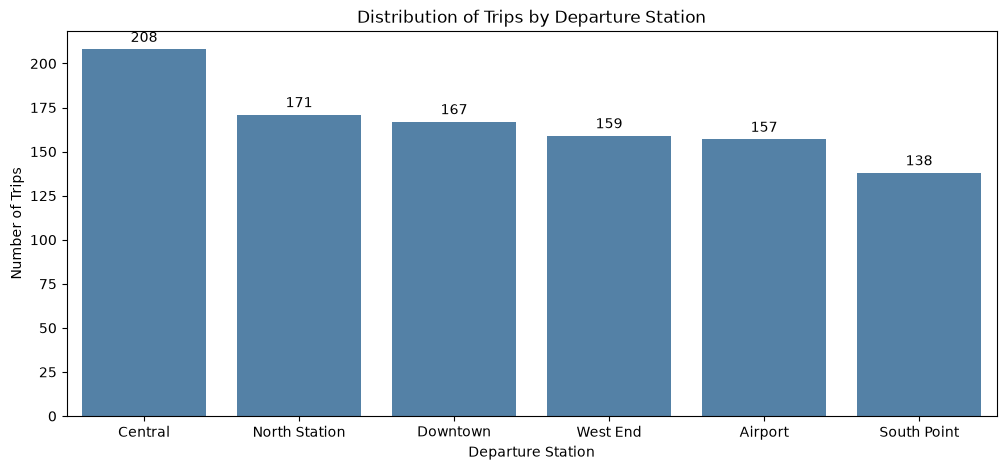

In [116]:
# Plot the distribution of trips by departure station
fig, ax = plt.subplots(figsize=(12, 5))

sns.countplot(
    data=df,
    x="Departure_Station",
    order=df["Departure_Station"].value_counts().index,
    color="steelblue",
    ax=ax
)

# Show trip counts above each bar
for container in ax.containers:
    ax.bar_label(container, padding=3)

ax.set_title("Distribution of Trips by Departure Station")
ax.set_xlabel("Departure Station")
ax.set_ylabel("Number of Trips")

plt.show()

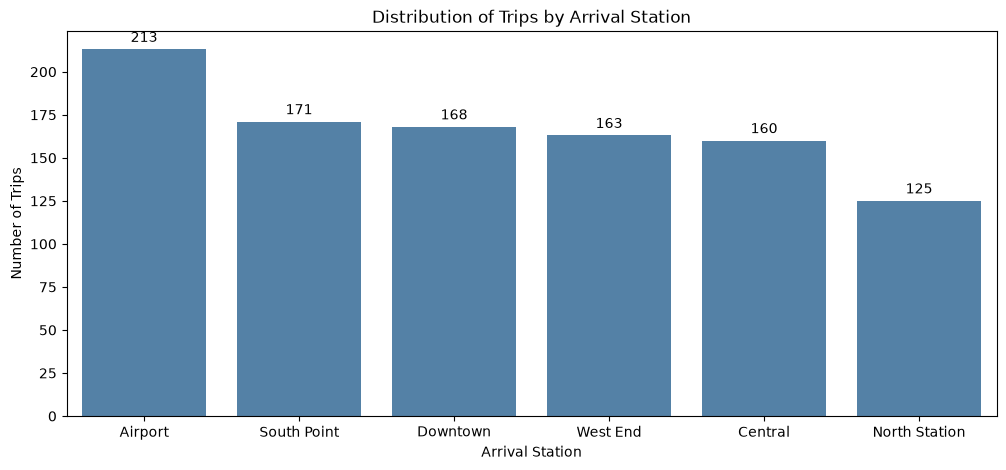

In [117]:
# Plot the distribution of trips by arrival station
fig, ax = plt.subplots(figsize=(12, 5))

sns.countplot(
    data=df,
    x="Arrival_Station",
    order=df["Arrival_Station"].value_counts().index,
    color="steelblue",
    ax=ax
)

# Show trip counts above each bar
for container in ax.containers:
    ax.bar_label(container, padding=3)

ax.set_title("Distribution of Trips by Arrival Station")
ax.set_xlabel("Arrival Station")
ax.set_ylabel("Number of Trips")

plt.show()

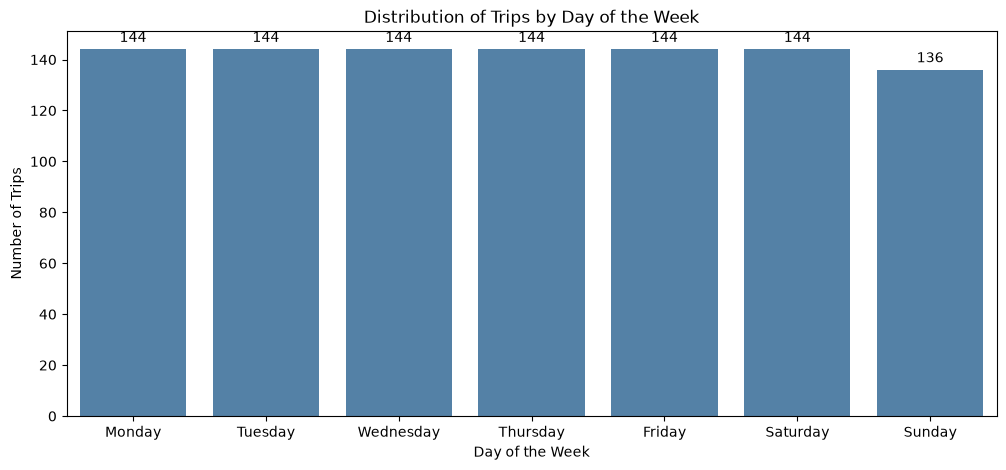

In [118]:
# Plot the distribution of trips by day of the week
fig, ax = plt.subplots(figsize=(12, 5))

day_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

sns.countplot(
    data=df,
    x="Day_of_Week",
    order=day_order,
    color="steelblue",
    ax=ax
)

# Show trip counts above each bar
for container in ax.containers:
    ax.bar_label(container, padding=3)

ax.set_title("Distribution of Trips by Day of the Week")
ax.set_xlabel("Day of the Week")
ax.set_ylabel("Number of Trips")

plt.show()

### Spread and potential outliers

The boxplots help me check the median, middle 50% and any points outside the usual 1.5 × IQR whiskers. I don't see any flagged outliers in these three numerical fields. That doesn't prove every value is correct; it only means there are no outliers by this particular rule.

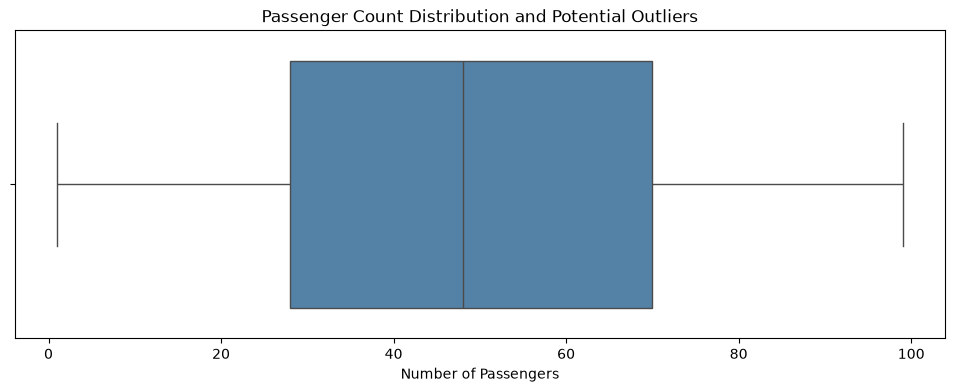

In [119]:
# Check passenger count distribution and potential outliers
fig, ax = plt.subplots(figsize=(12, 4))

sns.boxplot(
    data=df,
    x="Passenger_Count",
    color="steelblue",
    ax=ax
)

ax.set_title("Passenger Count Distribution and Potential Outliers")
ax.set_xlabel("Number of Passengers")

plt.show()

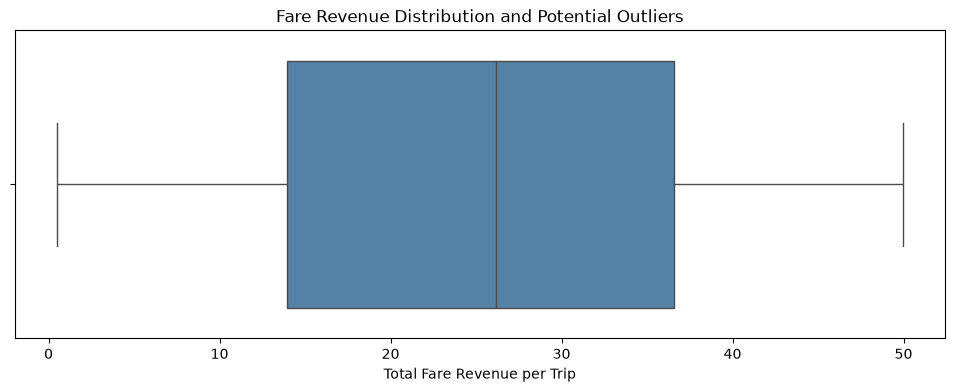

In [120]:
# Check fare revenue distribution and potential outliers
fig, ax = plt.subplots(figsize=(12, 4))

sns.boxplot(
    data=df,
    x="Fare_Amount",
    color="steelblue",
    ax=ax
)

ax.set_title("Fare Revenue Distribution and Potential Outliers")
ax.set_xlabel("Total Fare Revenue per Trip")

plt.show()

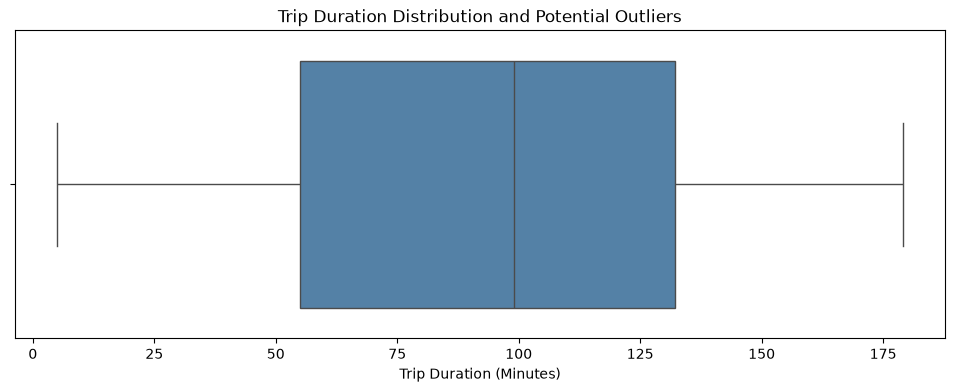

In [121]:
# Check trip duration distribution and potential outliers
fig, ax = plt.subplots(figsize=(12, 4))

sns.boxplot(
    data=df,
    x="Trip_Duration_Minutes",
    color="steelblue",
    ax=ax
)

ax.set_title("Trip Duration Distribution and Potential Outliers")
ax.set_xlabel("Trip Duration (Minutes)")

plt.show()

## 5. Bivariate analysis

I now compare pairs of variables. I use **totals** to see the overall contribution of a mode or station, and **averages per trip** to make comparisons less dependent on the number of services recorded. Neither of these measures, by itself, proves efficiency or profitability.

### Passenger and revenue comparisons

The combined charts show the difference between volume and trip-level averages. Bus has the highest total passengers and fare revenue, while Tram has the highest average passengers per trip and Train has the highest average fare revenue per trip. The station charts give the same comparison from a different angle.

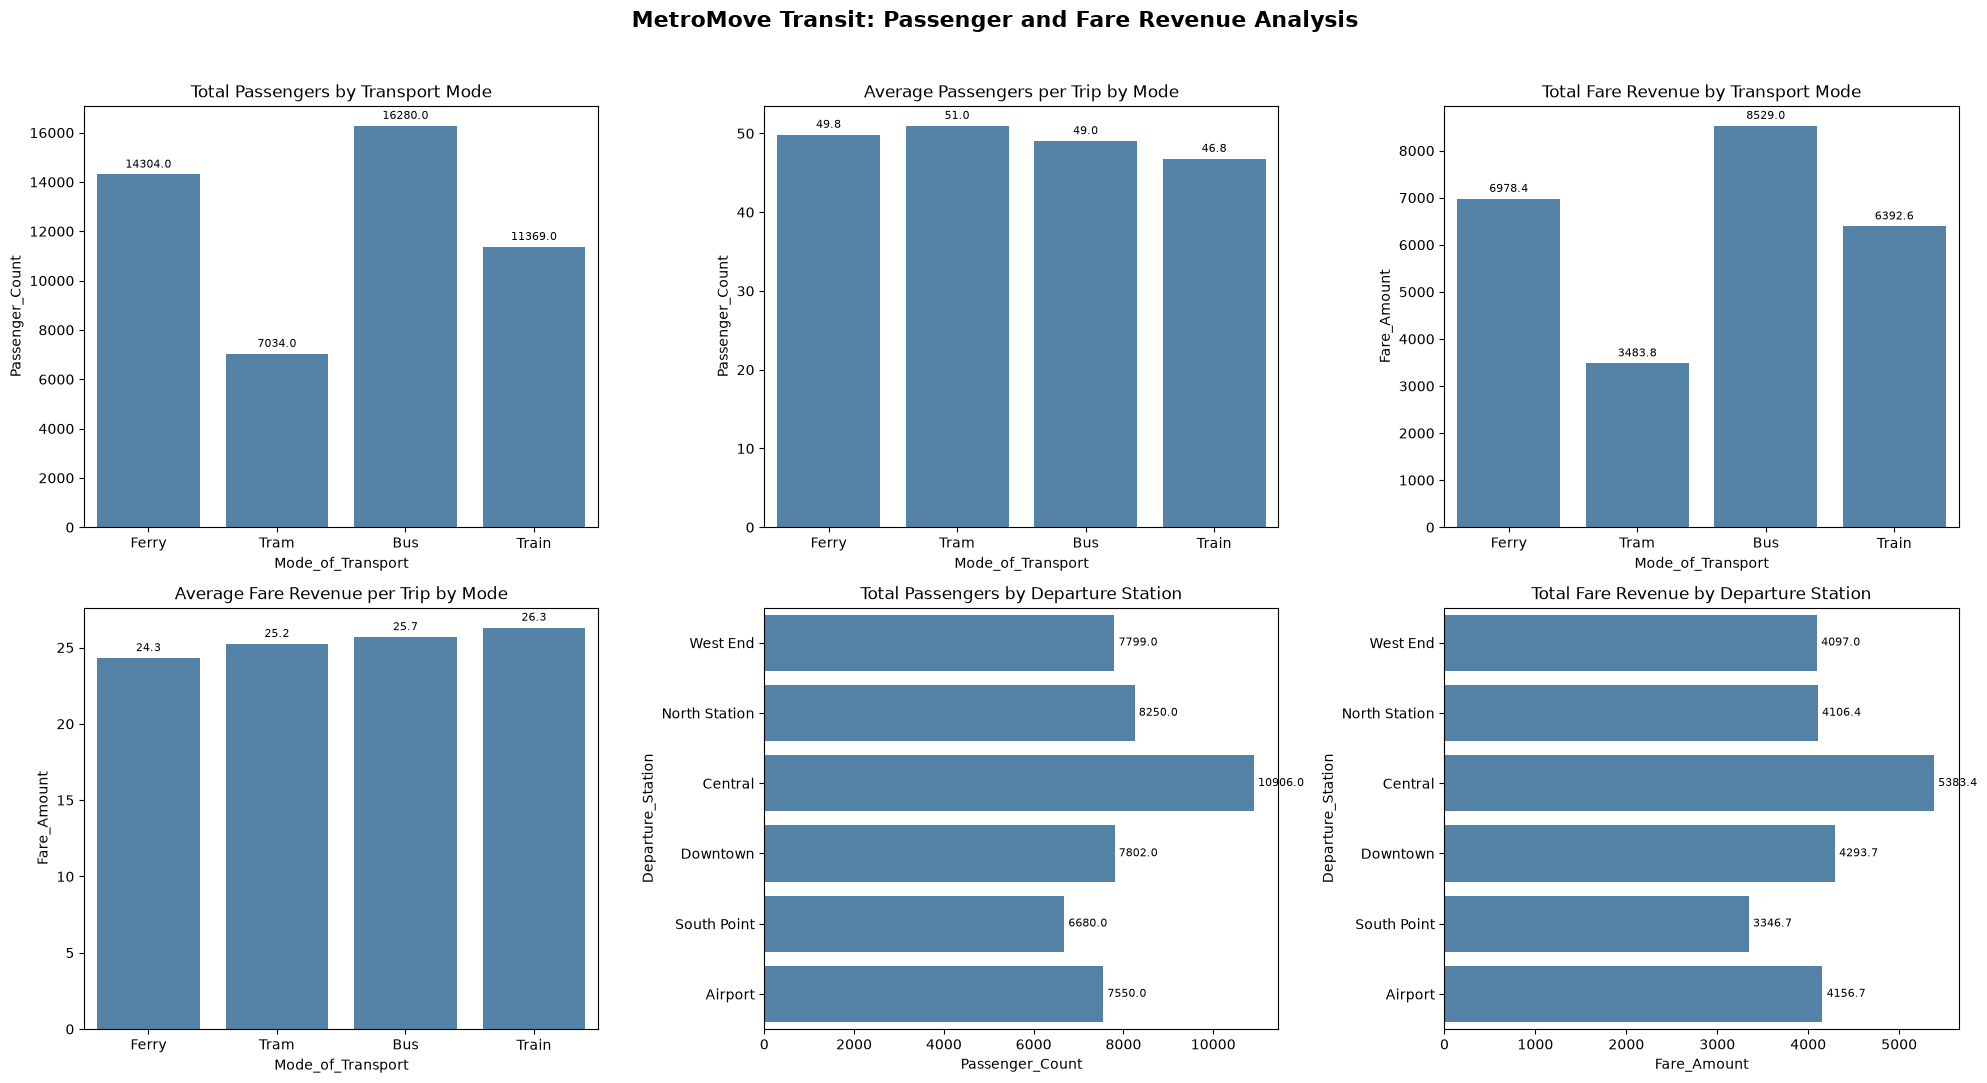

In [122]:
# Bivariate Analysis: Passenger Volume and Fare Revenue

fig, axes = plt.subplots(2, 3, figsize=(20, 11))

# Chart 1: Total passengers by transport mode
sns.barplot(
    data=df,
    x="Mode_of_Transport",
    y="Passenger_Count",
    estimator="sum",
    errorbar=None,
    color="steelblue",
    ax=axes[0, 0]
)
axes[0, 0].set_title("Total Passengers by Transport Mode")

# Chart 2: Average passengers per trip by transport mode
sns.barplot(
    data=df,
    x="Mode_of_Transport",
    y="Passenger_Count",
    estimator="mean",
    errorbar=None,
    color="steelblue",
    ax=axes[0, 1]
)
axes[0, 1].set_title("Average Passengers per Trip by Mode")

# Chart 3: Total fare revenue by transport mode
sns.barplot(
    data=df,
    x="Mode_of_Transport",
    y="Fare_Amount",
    estimator="sum",
    errorbar=None,
    color="steelblue",
    ax=axes[0, 2]
)
axes[0, 2].set_title("Total Fare Revenue by Transport Mode")

# Chart 4: Average fare revenue by transport mode
sns.barplot(
    data=df,
    x="Mode_of_Transport",
    y="Fare_Amount",
    estimator="mean",
    errorbar=None,
    color="steelblue",
    ax=axes[1, 0]
)
axes[1, 0].set_title("Average Fare Revenue per Trip by Mode")

# Chart 5: Total passengers by departure station
sns.barplot(
    data=df,
    y="Departure_Station",
    x="Passenger_Count",
    estimator="sum",
    errorbar=None,
    color="steelblue",
    ax=axes[1, 1]
)
axes[1, 1].set_title("Total Passengers by Departure Station")

# Chart 6: Total fare revenue by departure station
sns.barplot(
    data=df,
    y="Departure_Station",
    x="Fare_Amount",
    estimator="sum",
    errorbar=None,
    color="steelblue",
    ax=axes[1, 2]
)
axes[1, 2].set_title("Total Fare Revenue by Departure Station")

# Label the bars to all six charts
for ax in axes.flat:
    for container in ax.containers:
        ax.bar_label(container, fmt="%.1f", padding=3, fontsize=8)

plt.suptitle(
    "MetroMove Transit: Passenger and Fare Revenue Analysis",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

### How journey durations vary by mode

I compare average trip time with the full spread of durations. All four modes have broadly similar averages, but the boxplots show wide variation within each mode. Since I don't have route distances or delays, I can't rank their operational efficiency from duration alone.

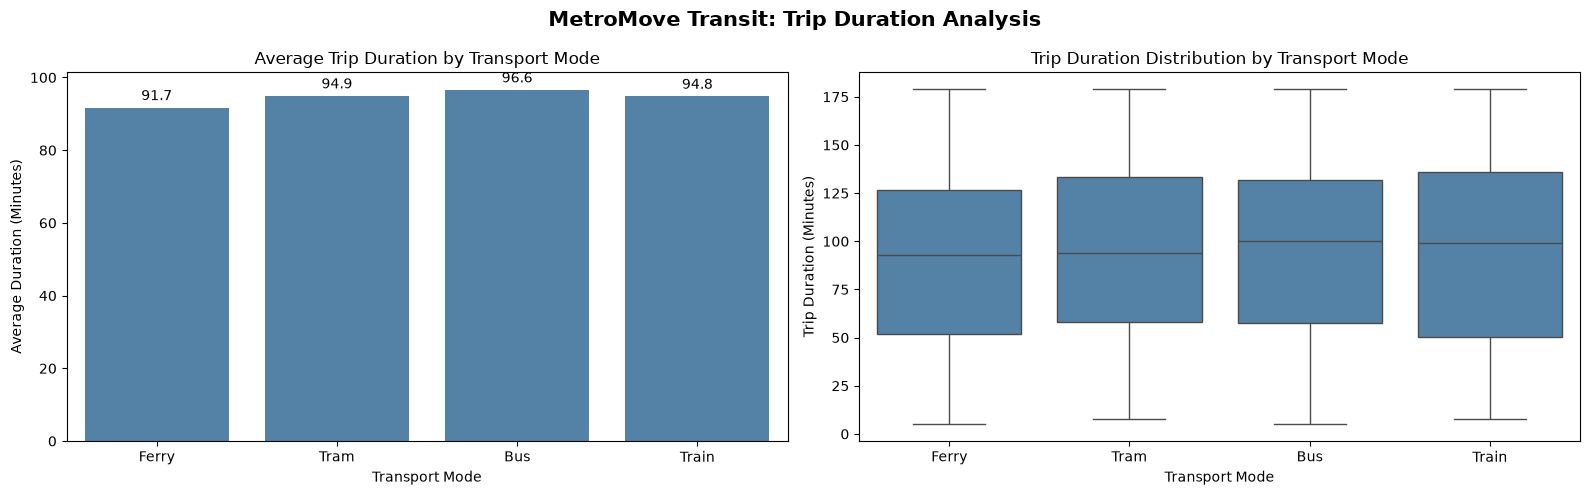

In [123]:
# Compare average trip duration and duration distribution by transport mode
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Chart 1: Average trip duration by transport mode
sns.barplot(
    data=df,
    x="Mode_of_Transport",
    y="Trip_Duration_Minutes",
    estimator="mean",
    errorbar=None,
    color="steelblue",
    ax=axes[0]
)

axes[0].set_title("Average Trip Duration by Transport Mode")
axes[0].set_xlabel("Transport Mode")
axes[0].set_ylabel("Average Duration (Minutes)")

for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.1f", padding=3)

# Chart 2: Trip duration distribution by transport mode
sns.boxplot(
    data=df,
    x="Mode_of_Transport",
    y="Trip_Duration_Minutes",
    color="steelblue",
    ax=axes[1]
)

axes[1].set_title("Trip Duration Distribution by Transport Mode")
axes[1].set_xlabel("Transport Mode")
axes[1].set_ylabel("Trip Duration (Minutes)")

plt.suptitle(
    "MetroMove Transit: Trip Duration Analysis",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

### Departures, arrivals and station balance

I use the same station order for arrivals and departures so differences are easy to spot. I then calculate **arrivals minus departures**. A positive result means more recorded arrivals; a negative result means more recorded departures. This is a trip count, not a measure of net passenger movement or vehicle shortages.

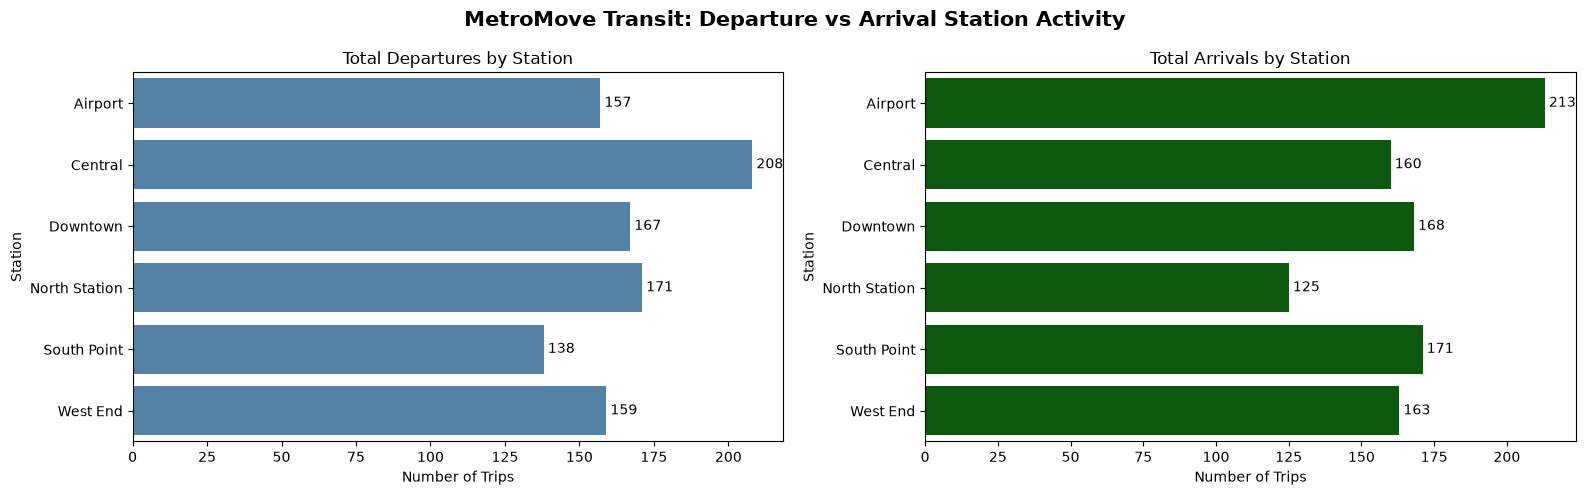

In [124]:
# Compare the number of departures and arrivals by station
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Use the same station order for both charts
station_order = sorted(df["Departure_Station"].unique())

# Chart 1: Total departures by station
sns.countplot(
    data=df,
    y="Departure_Station",
    order=station_order,
    color="steelblue",
    ax=axes[0]
)

axes[0].set_title("Total Departures by Station")
axes[0].set_xlabel("Number of Trips")
axes[0].set_ylabel("Station")

# Chart 2: Total arrivals by station
sns.countplot(
    data=df,
    y="Arrival_Station",
    order=station_order,
    color="darkgreen",
    ax=axes[1]
)

axes[1].set_title("Total Arrivals by Station")
axes[1].set_xlabel("Number of Trips")
axes[1].set_ylabel("Station")

# Add count labels
for ax in axes:
    for container in ax.containers:
        ax.bar_label(container, padding=3)

plt.suptitle(
    "MetroMove Transit: Departure vs Arrival Station Activity",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

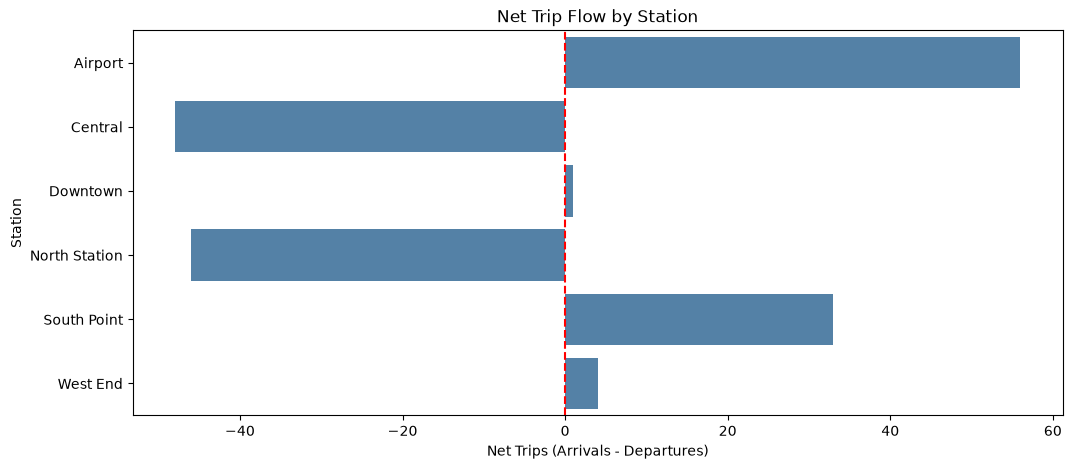

In [125]:
# Calculate net trip flow by station
departures = df["Departure_Station"].value_counts()
arrivals = df["Arrival_Station"].value_counts()

station_flow = pd.DataFrame({
    "Departures": departures,
    "Arrivals": arrivals
}).fillna(0)

station_flow["Net_Flow"] = (
    station_flow["Arrivals"] - station_flow["Departures"]
)

# Plot net trip flow by station
fig, ax = plt.subplots(figsize=(12, 5))

sns.barplot(
    data=station_flow.reset_index(),
    x="Net_Flow",
    y="index",
    color="steelblue",
    ax=ax
)

ax.axvline(0, color="red", linestyle="--")

ax.set_title("Net Trip Flow by Station")
ax.set_xlabel("Net Trips (Arrivals - Departures)")
ax.set_ylabel("Station")

plt.show()

### Route-level analysis

A route comes from the departure and arrival stations **on the same row**. For this analysis, direction matters: `Central → Airport` and `Airport → Central` are counted separately.

Some records start and end at the same station. I inspect them rather than removing them automatically, because a circular service is possible but not confirmed.

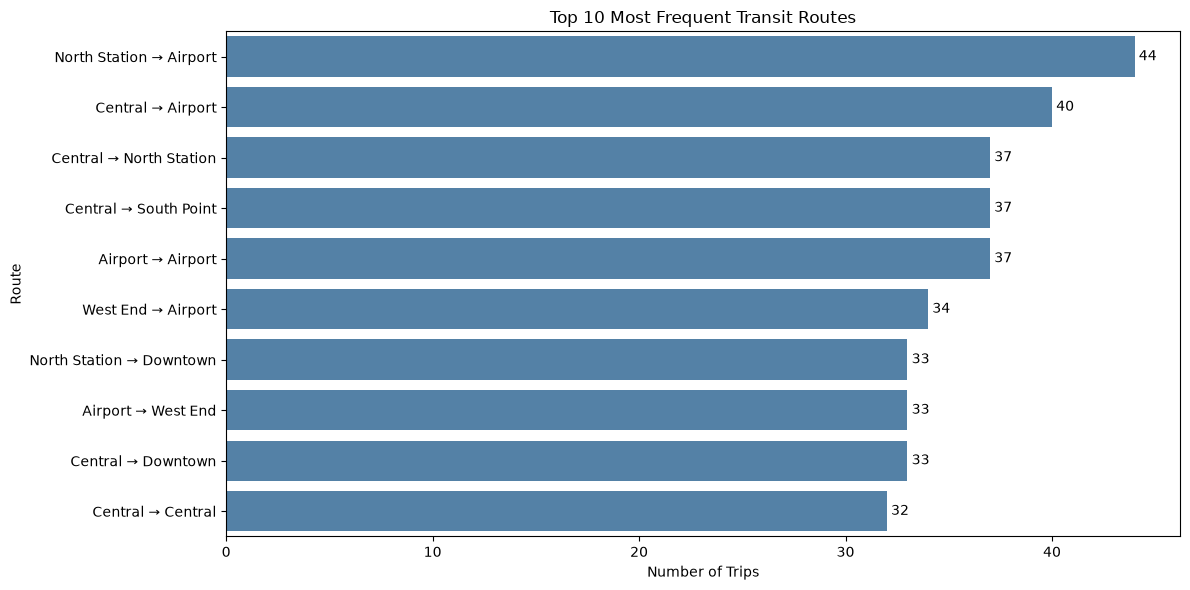

In [126]:
# Find the top 10 most frequently recorded routes

# Create a route column using departure and arrival stations
df["Route"] = (
    df["Departure_Station"] + " → " + df["Arrival_Station"]
)

# Count trips per route
top_routes = df["Route"].value_counts().head(10)

# Plot the top 10 routes
fig, ax = plt.subplots(figsize=(12, 6))

sns.barplot(
    x=top_routes.values,
    y=top_routes.index,
    color="steelblue",
    ax=ax
)

# Show trip counts to each bar
for container in ax.containers:
    ax.bar_label(container, padding=3)

ax.set_title("Top 10 Most Frequent Transit Routes")
ax.set_xlabel("Number of Trips")
ax.set_ylabel("Route")

plt.tight_layout()
plt.show()

### Same-station journeys

There are **164 same-station trips (16.4%)**. I compare their duration, passengers and revenue with journeys between different stations. The records contain meaningful values, but that alone cannot establish whether these are genuine circular routes or station-entry errors.

In [127]:
# Find trips where departure and arrival stations are the same
same_station = df[
    df["Departure_Station"] == df["Arrival_Station"]
]

# Count same-station trips by station
print("Total Same-Station Trips:", len(same_station))

same_station["Departure_Station"].value_counts()

Total Same-Station Trips: 164


Departure_Station
Airport          37
Central          32
Downtown         32
South Point      24
West End         23
North Station    16
Name: count, dtype: int64

In [128]:
# Display how departure and arrival stations form each route
df[[
    "Trip_ID",
    "Departure_Station",
    "Arrival_Station",
    "Route"
]].head(10)

,Trip_ID,Departure_Station,Arrival_Station,Route
0,TRIP0001,West End,Airport,West End → Airport
1,TRIP0002,North Station,Downtown,North Station → Downtown
2,TRIP0003,Central,North Station,Central → North Station
3,TRIP0004,Downtown,Central,Downtown → Central
4,TRIP0005,Downtown,Central,Downtown → Central
5,TRIP0006,South Point,South Point,South Point → South Point
6,TRIP0007,West End,West End,West End → West End
7,TRIP0008,Central,South Point,Central → South Point
8,TRIP0009,West End,North Station,West End → North Station
9,TRIP0010,Central,South Point,Central → South Point


In [129]:
# Check trip characteristics where departure and arrival stations are the same
same_station.groupby("Departure_Station").agg(
    Total_Trips=("Trip_ID", "count"),
    Avg_Duration=("Trip_Duration_Minutes", "mean"),
    Avg_Passengers=("Passenger_Count", "mean"),
    Avg_Fare=("Fare_Amount", "mean")
).round(2)

,Total_Trips,Avg_Duration,Avg_Passengers,Avg_Fare
Departure_Station,,,,
Airport,37,102.30,50.46,29.64
Central,32,104.72,51.19,22.84
Downtown,32,89.31,44.78,25.83
North Station,16,96.12,40.38,20.58
South Point,24,106.12,47.04,26.10
West End,23,95.78,47.13,20.51


In [130]:
# Compare same-station trips with different-station trips

df["Route_Type"] = (
    df["Departure_Station"] == df["Arrival_Station"]
).map({
    True: "Same Station",
    False: "Different Stations"
})

df.groupby("Route_Type").agg(
    Total_Trips=("Trip_ID", "count"),
    Avg_Duration=("Trip_Duration_Minutes", "mean"),
    Avg_Passengers=("Passenger_Count", "mean"),
    Avg_Fare=("Fare_Amount", "mean")
).round(2)

,Total_Trips,Avg_Duration,Avg_Passengers,Avg_Fare
Route_Type,,,,
Different Stations,836,93.60,49.27,25.48
Same Station,164,99.28,47.54,24.89


### Which routes account for passengers and revenue?

The busiest route by frequency does not have to lead in fare revenue. I rank routes separately by passenger totals and fare totals, then look at average duration and revenue per trip for the **same ten most frequent routes**. This keeps the comparison consistent.

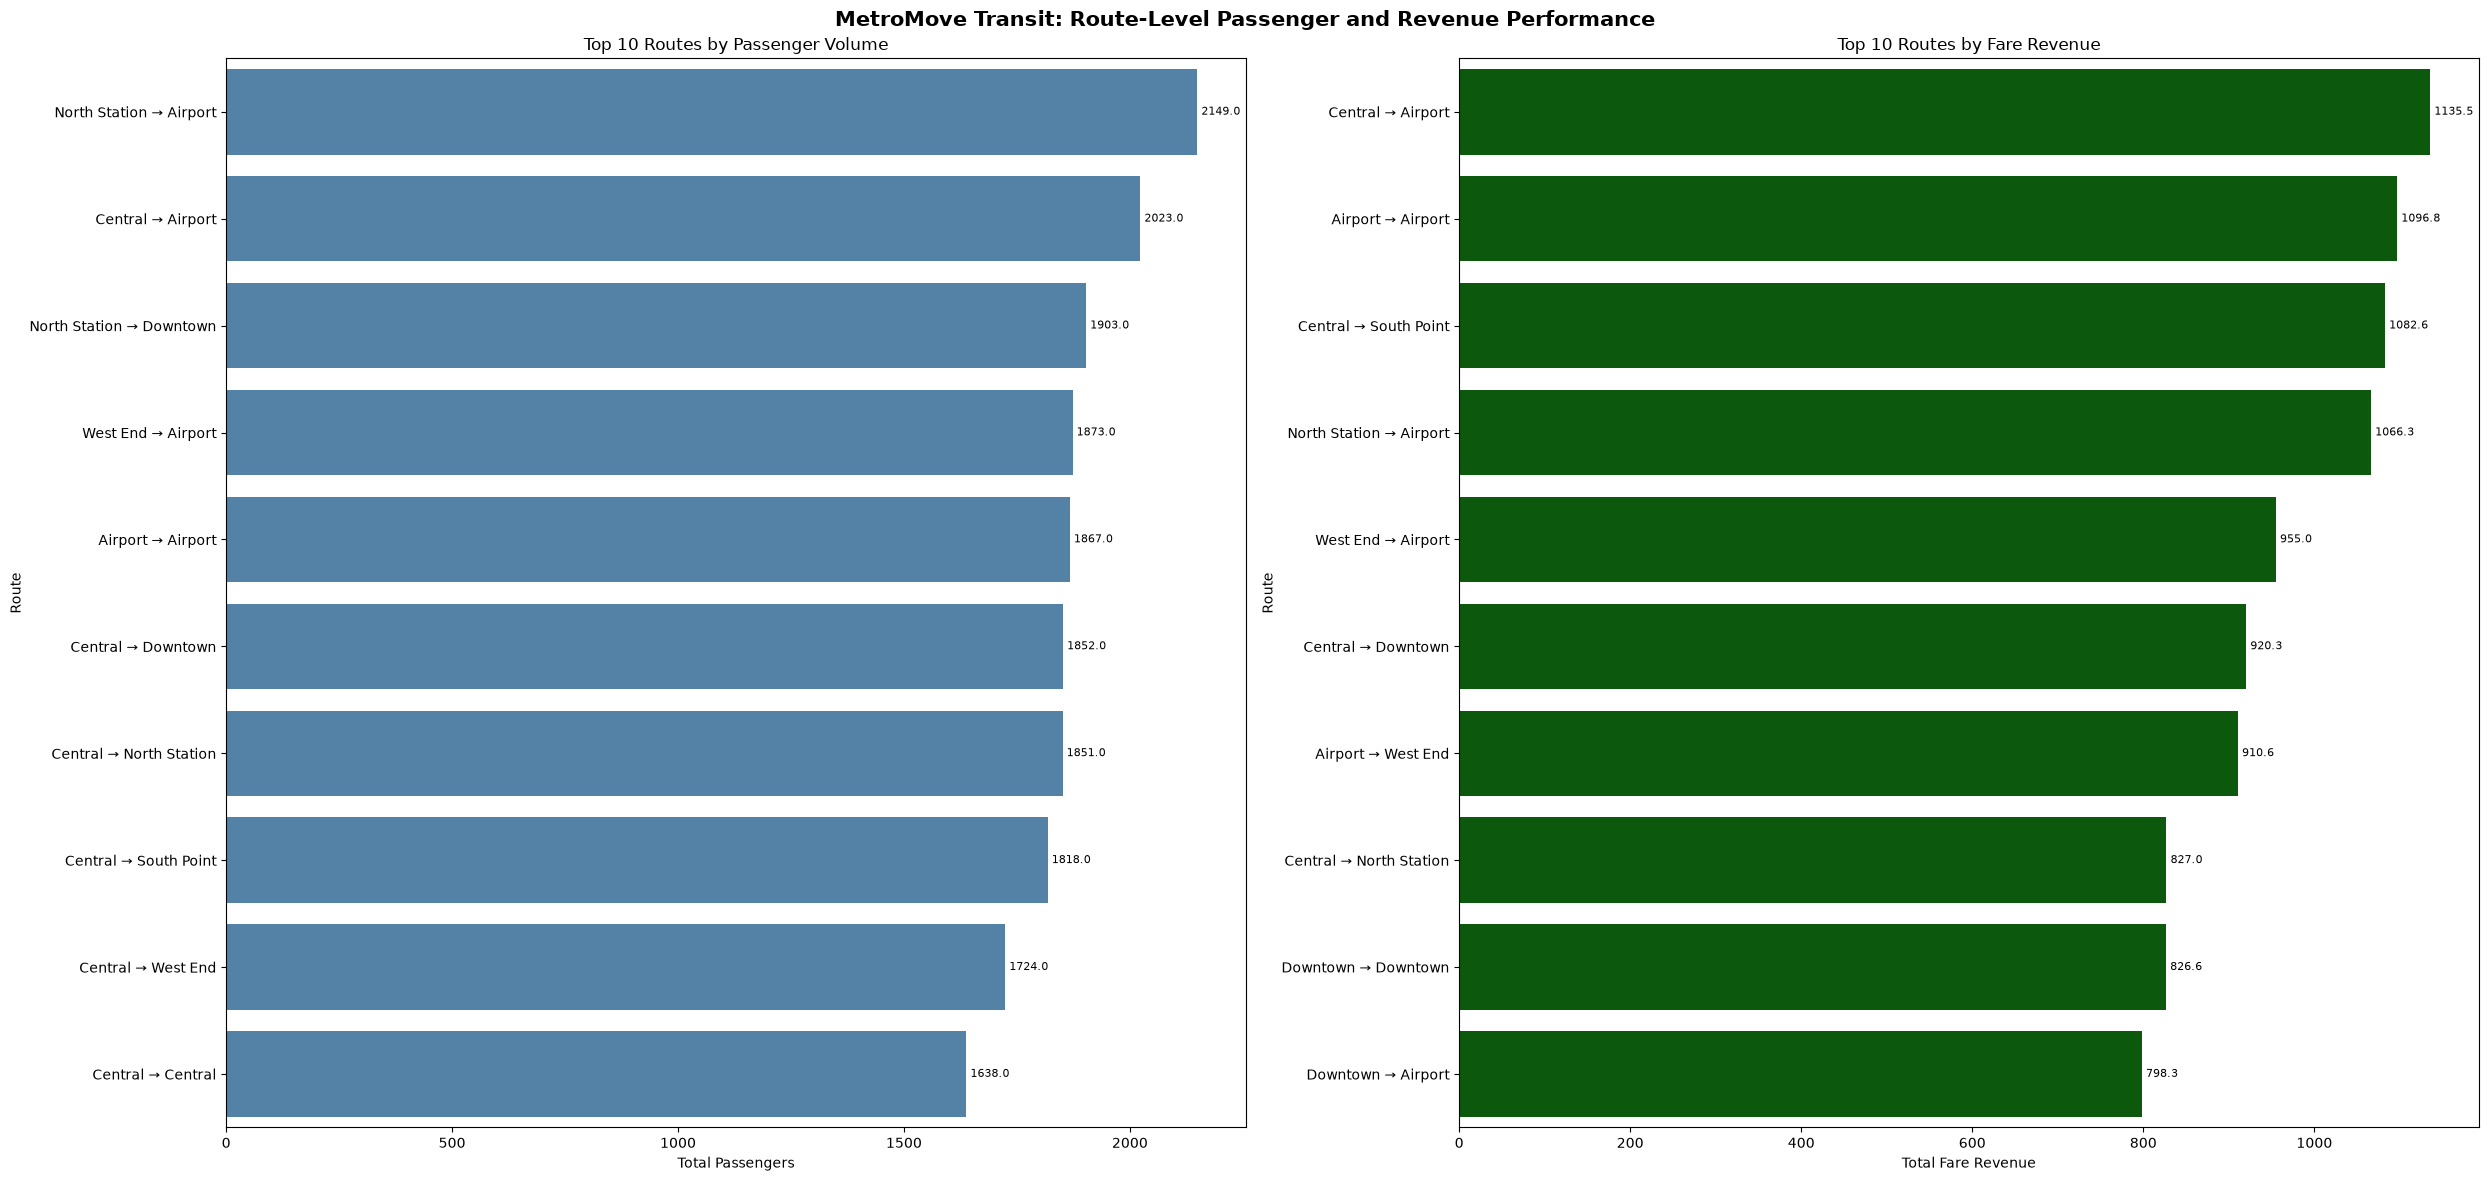

In [131]:
# Compare top 10 routes by passenger volume and fare revenue

route_summary = df.groupby("Route").agg(
    Total_Trips=("Trip_ID", "count"),
    Total_Passengers=("Passenger_Count", "sum"),
    Total_Revenue=("Fare_Amount", "sum")
)

fig, axes = plt.subplots(1, 2, figsize=(25, 12))

# Chart 1: Top 10 routes by passenger volume
top_passenger_routes = route_summary.nlargest(10, "Total_Passengers")

sns.barplot(
    data=top_passenger_routes,
    x="Total_Passengers",
    y=top_passenger_routes.index,
    color="steelblue",
    ax=axes[0]
)

axes[0].set_title("Top 10 Routes by Passenger Volume")
axes[0].set_xlabel("Total Passengers")
axes[0].set_ylabel("Route")

# Chart 2: Top 10 routes by fare revenue
top_revenue_routes = route_summary.nlargest(10, "Total_Revenue")

sns.barplot(
    data=top_revenue_routes,
    x="Total_Revenue",
    y=top_revenue_routes.index,
    color="darkgreen",
    ax=axes[1]
)

axes[1].set_title("Top 10 Routes by Fare Revenue")
axes[1].set_xlabel("Total Fare Revenue")
axes[1].set_ylabel("Route")

# Label the bars to both charts
for ax in axes:
    for container in ax.containers:
        ax.bar_label(container, fmt="%.1f", padding=3, fontsize=8)

plt.suptitle(
    "MetroMove Transit: Route-Level Passenger and Revenue Performance",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

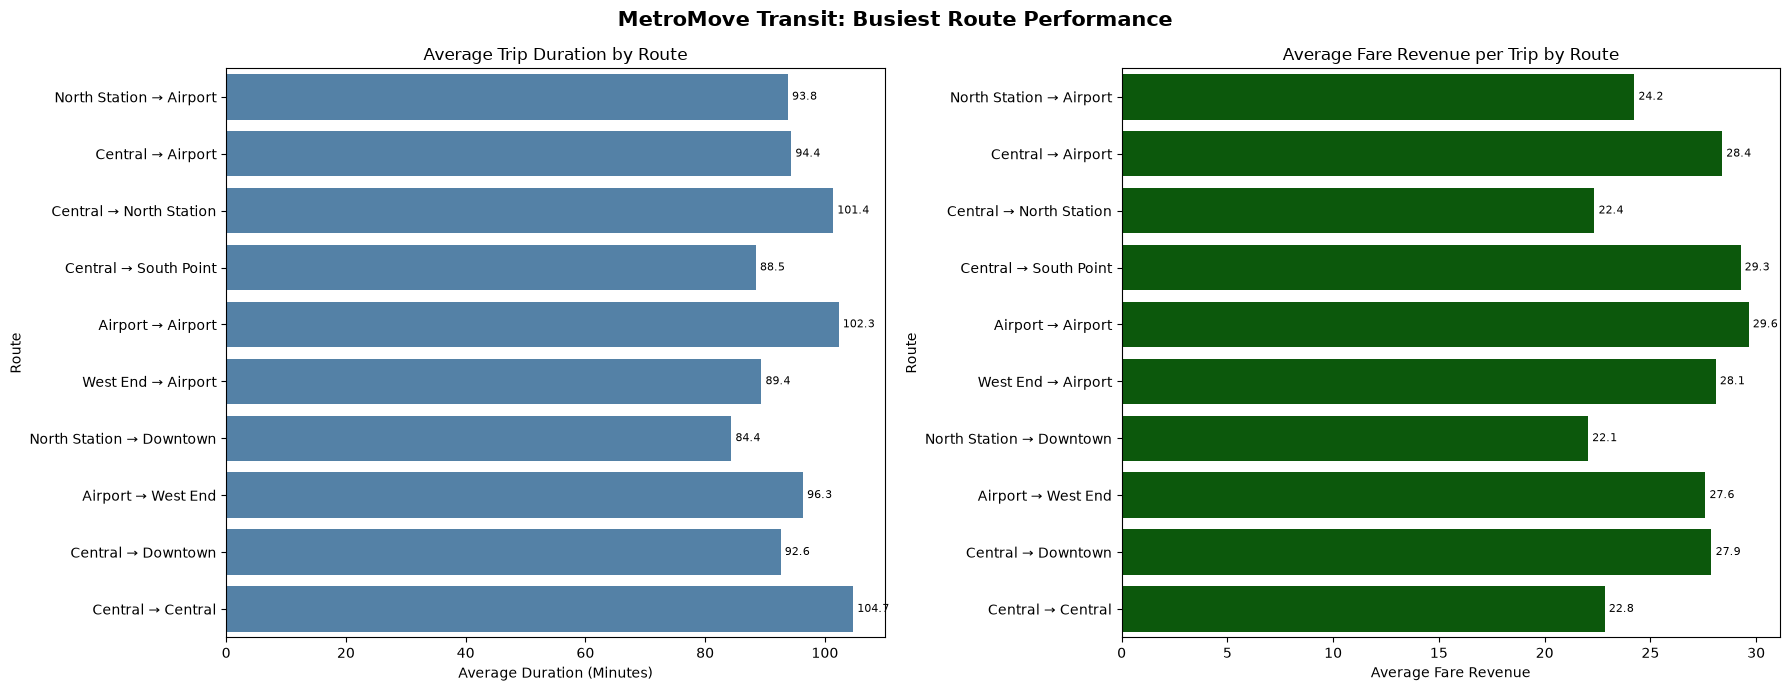

In [132]:
# Compare average duration and fare revenue for the 10 busiest routes

top_10_routes = df["Route"].value_counts().head(10).index

route_performance = (
    df[df["Route"].isin(top_10_routes)]
    .groupby("Route")
    .agg(
        Avg_Duration=("Trip_Duration_Minutes", "mean"),
        Avg_Fare=("Fare_Amount", "mean")
    )
    .reindex(top_10_routes)
)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Chart 1: Average trip duration
sns.barplot(
    data=route_performance,
    x="Avg_Duration",
    y=route_performance.index,
    color="steelblue",
    ax=axes[0]
)

axes[0].set_title("Average Trip Duration by Route")
axes[0].set_xlabel("Average Duration (Minutes)")
axes[0].set_ylabel("Route")

# Chart 2: Average fare revenue
sns.barplot(
    data=route_performance,
    x="Avg_Fare",
    y=route_performance.index,
    color="darkgreen",
    ax=axes[1]
)

axes[1].set_title("Average Fare Revenue per Trip by Route")
axes[1].set_xlabel("Average Fare Revenue")
axes[1].set_ylabel("Route")

# Label the bars
for ax in axes:
    for container in ax.containers:
        ax.bar_label(container, fmt="%.1f", padding=3, fontsize=8)

plt.suptitle(
    "MetroMove Transit: Busiest Route Performance",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

### Trip duration and fare revenue

I check whether longer trips tend to collect more fare revenue, first overall and then by mode. I use originally recorded fare and duration values for these scatter plots so the fitted lines are not shaped by my median replacements. Any trend here is an association, not proof of a fare-setting rule.

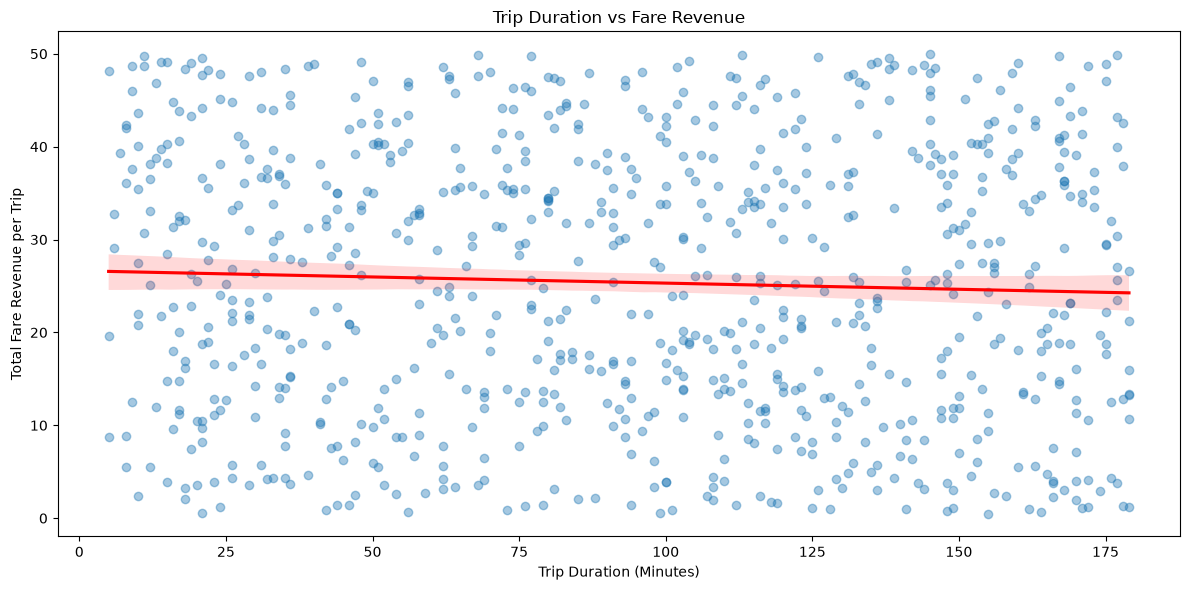

In [133]:
# Check the relationship between trip duration and fare revenue
fig, ax = plt.subplots(figsize=(12, 6))

# Use only originally recorded fares and durations
valid_trips = df.loc[
    ~df["Fare_Amount_Imputed"] &
    ~df["Trip_Duration_Imputed"]
]

sns.regplot(
    data=valid_trips,
    x="Trip_Duration_Minutes",
    y="Fare_Amount",
    scatter_kws={"alpha": 0.4},
    line_kws={"color": "red"},
    ax=ax
)

ax.set_title("Trip Duration vs Fare Revenue")
ax.set_xlabel("Trip Duration (Minutes)")
ax.set_ylabel("Total Fare Revenue per Trip")

plt.tight_layout()
plt.show()

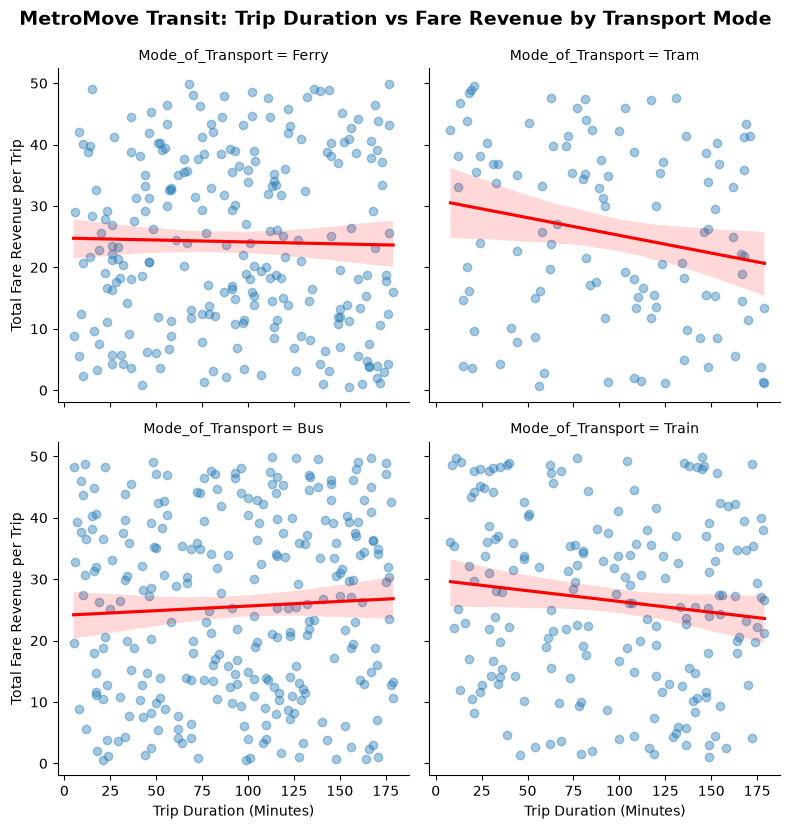

In [134]:
# Check trip duration vs fare revenue separately by transport mode
fig = sns.lmplot(
    data=valid_trips,
    x="Trip_Duration_Minutes",
    y="Fare_Amount",
    col="Mode_of_Transport",
    col_wrap=2,
    height=4,
    scatter_kws={"alpha": 0.4},
    line_kws={"color": "red"}
)

fig.set_axis_labels(
    "Trip Duration (Minutes)",
    "Total Fare Revenue per Trip"
)

fig.fig.suptitle(
    "MetroMove Transit: Trip Duration vs Fare Revenue by Transport Mode",
    fontsize=14,
    fontweight="bold",
    y=1.03
)

plt.show()

### Daily trends

Using the provisional `Trip_Date`, I compare daily passenger totals and fare revenue. Most days have **24 recorded trips**, but 11 February has only **16**, so a decline in the final day's total could partly reflect incomplete coverage.

I also look at **averages per trip** so the final day can be compared more fairly. That removes the trip-count difference, although it does not resolve the underlying date-quality problem.

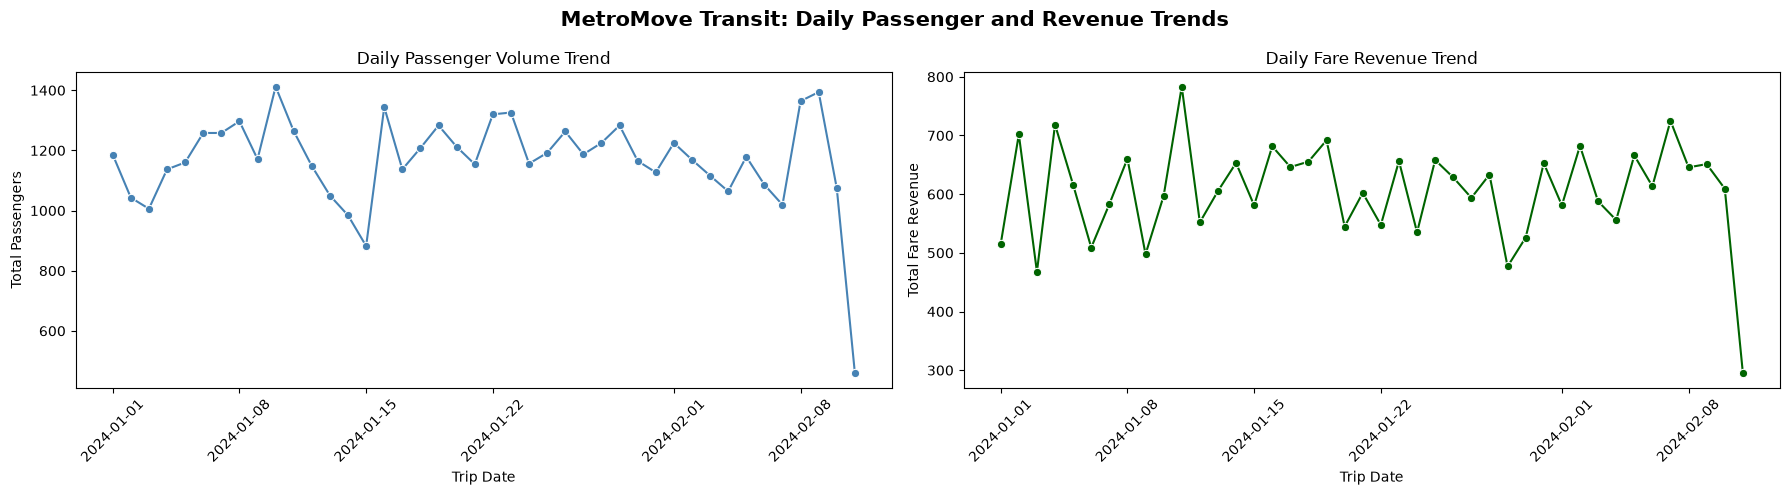

In [135]:
# Check daily passenger demand and fare revenue trends

# Aggregate passenger counts and fare revenue by trip date
daily_trends = df.groupby("Trip_Date").agg(
    Total_Passengers=("Passenger_Count", "sum"),
    Total_Revenue=("Fare_Amount", "sum")
).reset_index()

# Create two subplots
fig, axes = plt.subplots(1, 2, figsize=(18, 5))

# Chart 1: Daily passenger volume
sns.lineplot(
    data=daily_trends,
    x="Trip_Date",
    y="Total_Passengers",
    marker="o",
    color="steelblue",
    ax=axes[0]
)

axes[0].set_title("Daily Passenger Volume Trend")
axes[0].set_xlabel("Trip Date")
axes[0].set_ylabel("Total Passengers")
axes[0].tick_params(axis="x", rotation=45)

# Chart 2: Daily fare revenue
sns.lineplot(
    data=daily_trends,
    x="Trip_Date",
    y="Total_Revenue",
    marker="o",
    color="darkgreen",
    ax=axes[1]
)

axes[1].set_title("Daily Fare Revenue Trend")
axes[1].set_xlabel("Trip Date")
axes[1].set_ylabel("Total Fare Revenue")
axes[1].tick_params(axis="x", rotation=45)

plt.suptitle(
    "MetroMove Transit: Daily Passenger and Revenue Trends",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

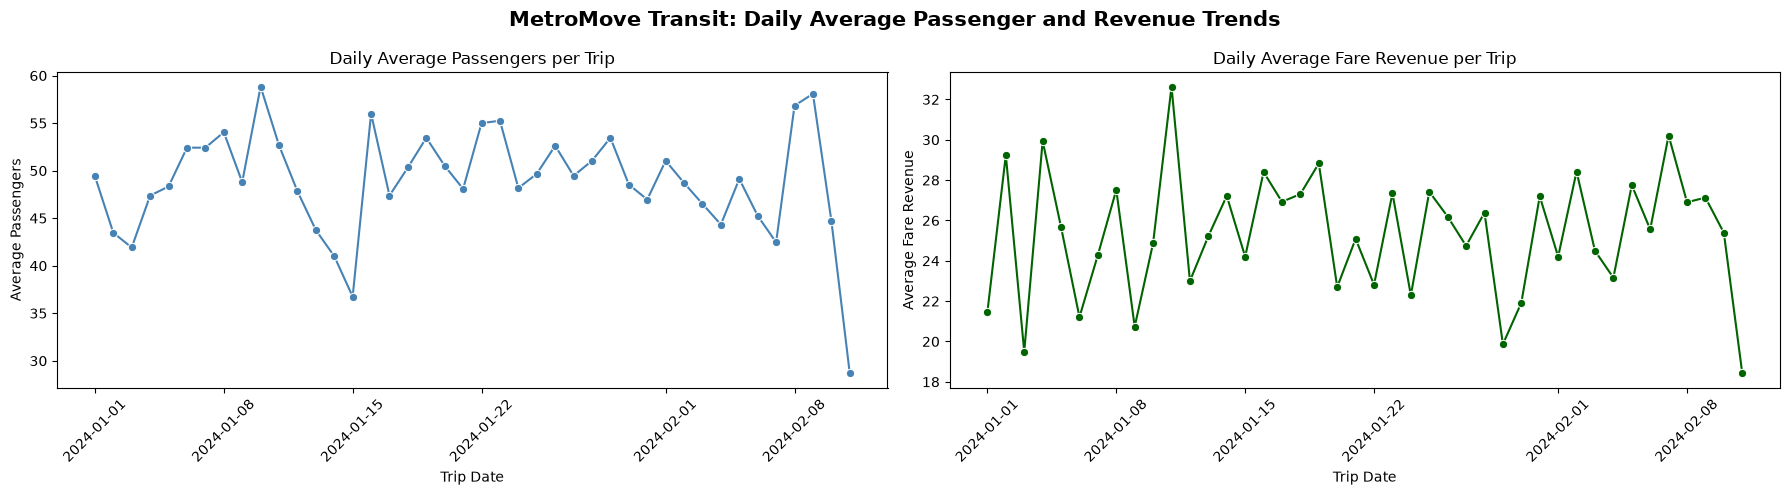

In [136]:
# Check daily average passengers and fare revenue per trip
daily_avg = df.groupby("Trip_Date").agg(
    Avg_Passengers=("Passenger_Count", "mean"),
    Avg_Revenue=("Fare_Amount", "mean")
).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(18, 5))

# Chart 1: Average passengers per trip
sns.lineplot(
    data=daily_avg,
    x="Trip_Date",
    y="Avg_Passengers",
    marker="o",
    color="steelblue",
    ax=axes[0]
)

axes[0].set_title("Daily Average Passengers per Trip")
axes[0].set_xlabel("Trip Date")
axes[0].set_ylabel("Average Passengers")
axes[0].tick_params(axis="x", rotation=45)

# Chart 2: Average fare revenue per trip
sns.lineplot(
    data=daily_avg,
    x="Trip_Date",
    y="Avg_Revenue",
    marker="o",
    color="darkgreen",
    ax=axes[1]
)

axes[1].set_title("Daily Average Fare Revenue per Trip")
axes[1].set_xlabel("Trip Date")
axes[1].set_ylabel("Average Fare Revenue")
axes[1].tick_params(axis="x", rotation=45)

plt.suptitle(
    "MetroMove Transit: Daily Average Passenger and Revenue Trends",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

### Daily passenger averages versus daily revenue averages

The daily scatter plot asks a slightly different question from the individual-trip plots: do days with higher **average passengers per trip** also show higher **average fare revenue per trip**? I calculate the Pearson coefficient to quantify the linear relationship rather than relying only on the red line.

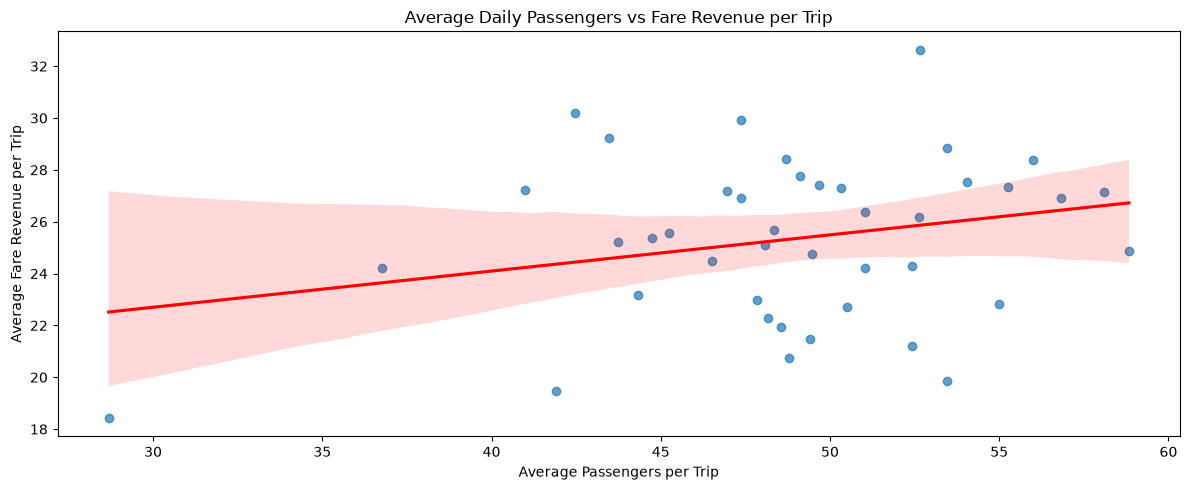

In [137]:
# Check the relationship between average daily passengers and fare revenue
fig, ax = plt.subplots(figsize=(12, 5))

sns.regplot(
    data=daily_avg,
    x="Avg_Passengers",
    y="Avg_Revenue",
    scatter_kws={"alpha": 0.7},
    line_kws={"color": "red"},
    ax=ax
)

ax.set_title("Average Daily Passengers vs Fare Revenue per Trip")
ax.set_xlabel("Average Passengers per Trip")
ax.set_ylabel("Average Fare Revenue per Trip")

plt.tight_layout()
plt.show()

In [138]:
# Calculate Pearson correlation between daily average passengers and fare revenue
correlation = daily_avg["Avg_Passengers"].corr(
    daily_avg["Avg_Revenue"]
)

print(f"Pearson Correlation: {correlation:.3f}")

Pearson Correlation: 0.256


## 6. Multivariate analysis

I bring more variables together here: numerical correlations, differences between transport modes and route types, weekday comparisons, and station-level breakdowns. I also check whether filling missing values materially changed the numerical correlations.

### Correlations before and after imputation

I compare a **complete-case sample** (733 trips with none of the three numerical fields imputed) with the full cleaned dataset (1,000 trips). The correlations are all near zero in both versions. This makes the linear-relationship findings less sensitive to the particular median imputation I used, but it does not rule out other imputation effects or non-linear relationships.

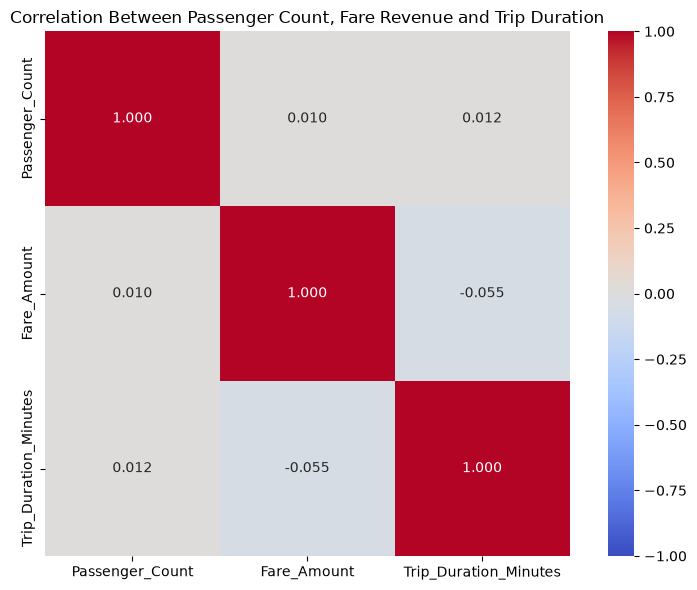

In [139]:
# Check linear relationships using trips with all three original measurements
numeric_cols = ["Passenger_Count", "Fare_Amount", "Trip_Duration_Minutes"]
original_data = df.loc[
    ~df["Passenger_Count_Imputed"]
    & ~df["Fare_Amount_Imputed"]
    & ~df["Trip_Duration_Imputed"]
]
corr_matrix = original_data[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(
    corr_matrix, annot=True, fmt=".3f", cmap="coolwarm",
    vmin=-1, vmax=1, center=0, square=True, ax=ax
)
ax.set_title("Correlation Between Passenger Count, Fare Revenue and Trip Duration")
plt.tight_layout()
plt.show()

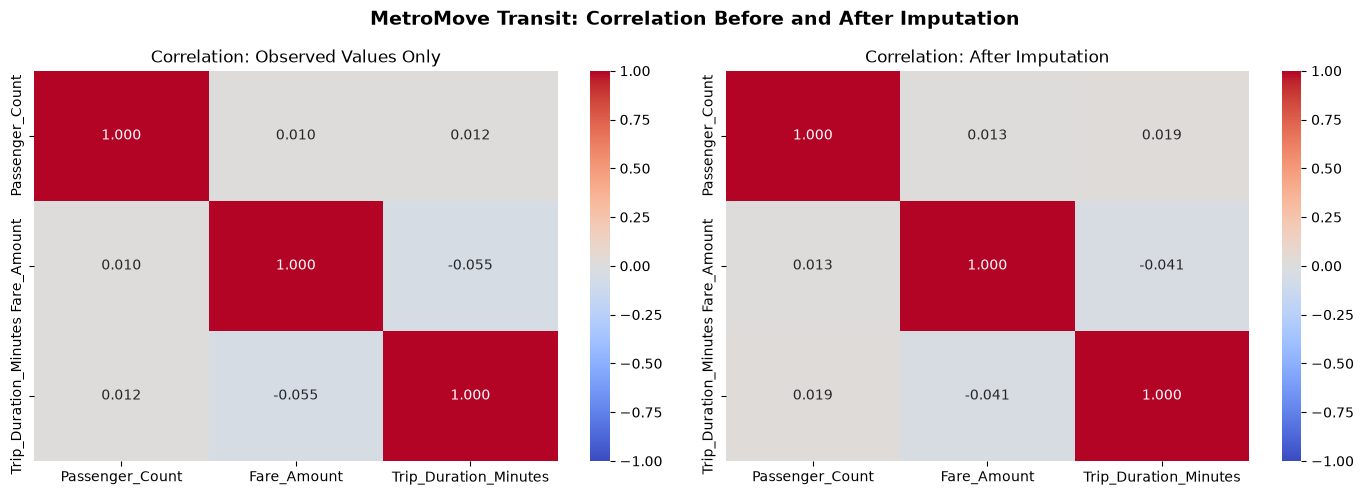

In [140]:
# Compare correlations using observed and imputed values
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Correlation using only originally recorded values
corr_original = original_data[numeric_cols].corr()

# Correlation using the complete cleaned dataset
corr_cleaned = df[numeric_cols].corr()

# Heatmap 1: Originally recorded values
sns.heatmap(
    corr_original,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    ax=axes[0]
)

axes[0].set_title("Correlation: Observed Values Only")

# Heatmap 2: Cleaned dataset with imputation
sns.heatmap(
    corr_cleaned,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    ax=axes[1]
)

axes[1].set_title("Correlation: After Imputation")

plt.suptitle(
    "MetroMove Transit: Correlation Before and After Imputation",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

### Transport mode and route type differences

The coloured scatter plot shows how passenger and fare values overlap across modes. The grouped duration charts then compare same-station and different-station trips within each mode. These plots show differences worth noting, not confirmed causes.

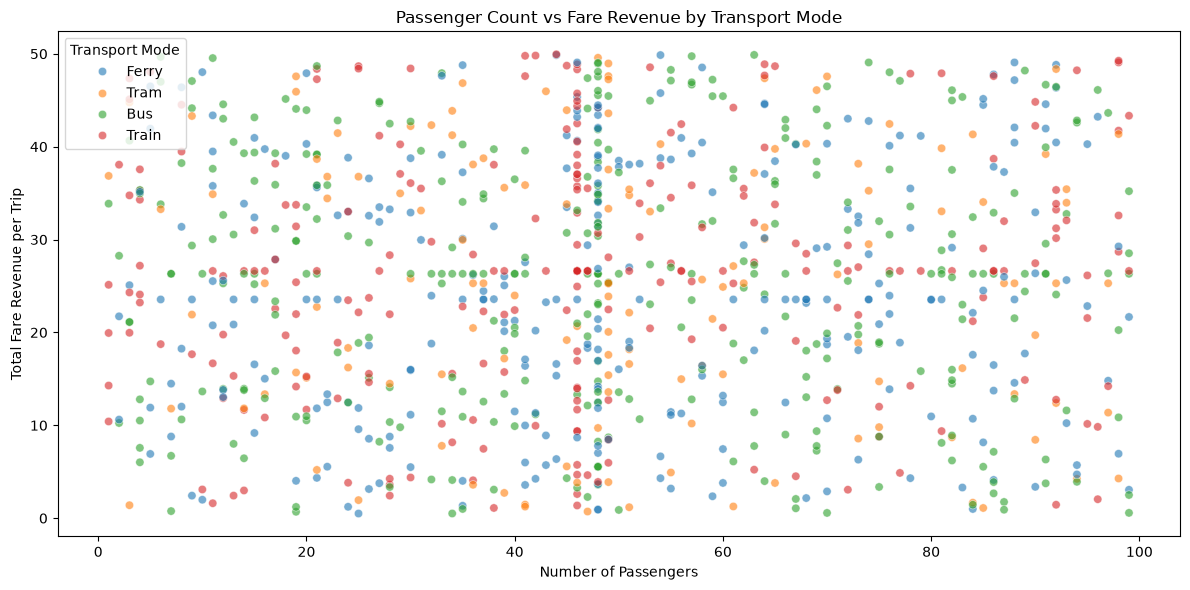

In [141]:
# Check passenger count vs fare revenue across transport modes
fig, ax = plt.subplots(figsize=(12, 6))

sns.scatterplot(
    data=df,
    x="Passenger_Count",
    y="Fare_Amount",
    hue="Mode_of_Transport",
    alpha=0.6,
    ax=ax
)

ax.set_title("Passenger Count vs Fare Revenue by Transport Mode")
ax.set_xlabel("Number of Passengers")
ax.set_ylabel("Total Fare Revenue per Trip")
ax.legend(title="Transport Mode")

plt.tight_layout()
plt.show()

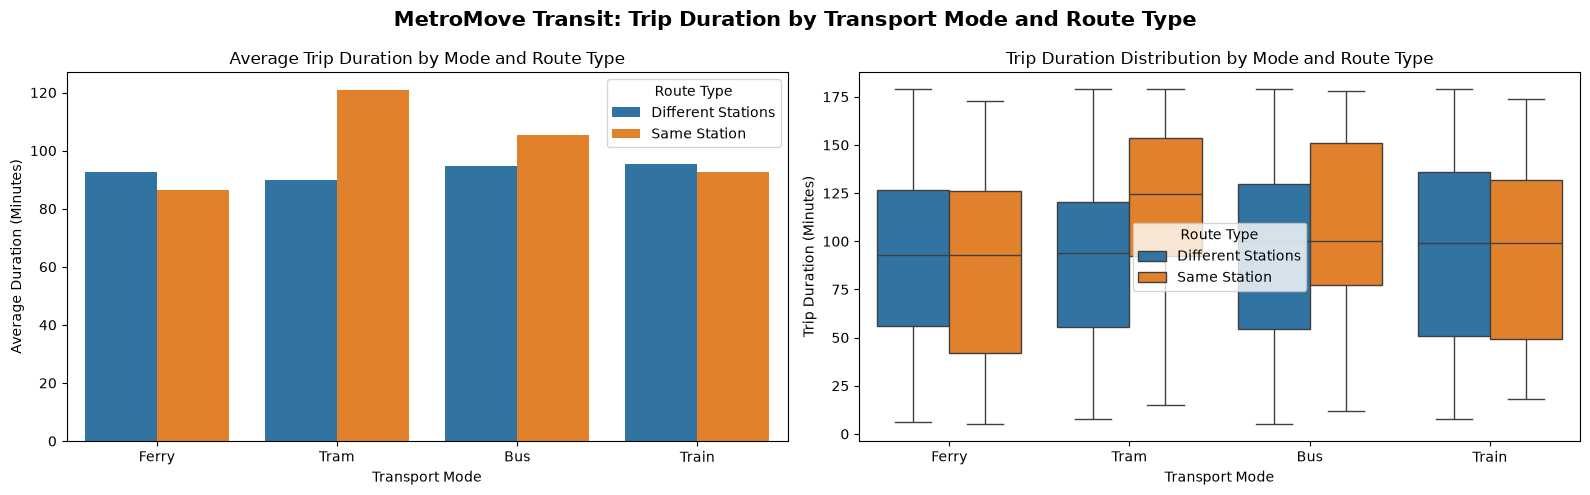

In [142]:
# Compare trip duration by transport mode and route type
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Chart 1: Average trip duration
sns.barplot(
    data=df,
    x="Mode_of_Transport",
    y="Trip_Duration_Minutes",
    hue="Route_Type",
    estimator="mean",
    errorbar=None,
    ax=axes[0]
)

axes[0].set_title("Average Trip Duration by Mode and Route Type")
axes[0].set_xlabel("Transport Mode")
axes[0].set_ylabel("Average Duration (Minutes)")
axes[0].legend(title="Route Type")

# Chart 2: Trip duration distribution
sns.boxplot(
    data=df,
    x="Mode_of_Transport",
    y="Trip_Duration_Minutes",
    hue="Route_Type",
    ax=axes[1]
)

axes[1].set_title("Trip Duration Distribution by Mode and Route Type")
axes[1].set_xlabel("Transport Mode")
axes[1].set_ylabel("Trip Duration (Minutes)")
axes[1].legend(title="Route Type")

plt.suptitle(
    "MetroMove Transit: Trip Duration by Transport Mode and Route Type",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

### Weekday, station and mode comparisons

The heatmaps let me compare average passengers and revenue across weekdays and services, then look at the station breakdown. I use both totals and per-trip averages where useful: a station with more trips will often have a larger total even if a typical trip is not especially busy.

Weekday findings are exploratory because `Day_of_Week` was calculated from the provisional trip dates.

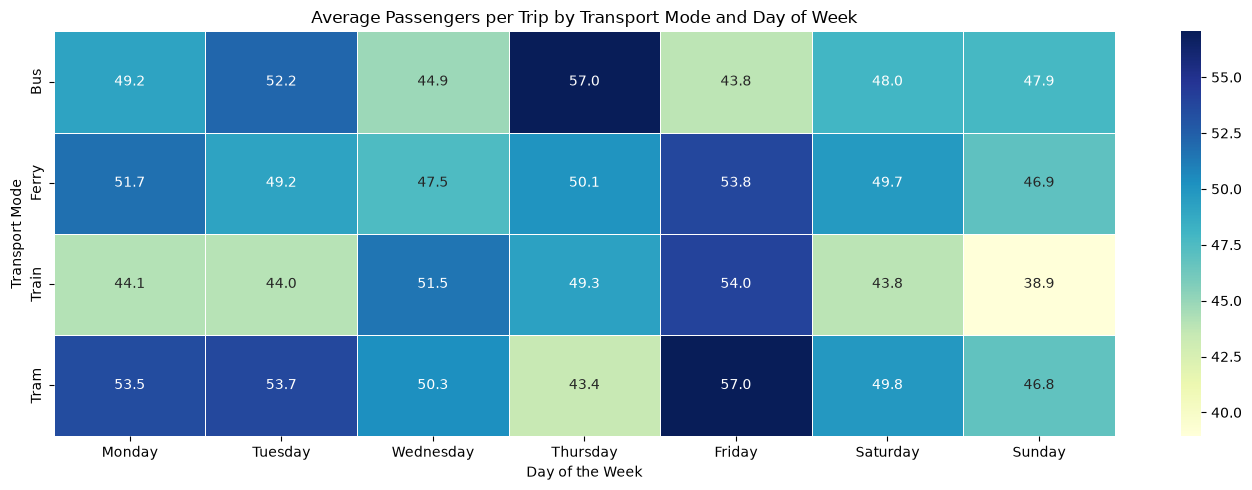

In [143]:
# Compare average passenger counts by transport mode and weekday

day_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

# Create a pivot table of average passenger counts
passenger_heatmap = df.pivot_table(
    index="Mode_of_Transport",
    columns="Day_of_Week",
    values="Passenger_Count",
    aggfunc="mean"
).reindex(columns=day_order)

# Plot passenger activity across weekdays and transport modes
fig, ax = plt.subplots(figsize=(14, 5))

sns.heatmap(
    passenger_heatmap,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    linewidths=0.5,
    ax=ax
)

ax.set_title("Average Passengers per Trip by Transport Mode and Day of Week")
ax.set_xlabel("Day of the Week")
ax.set_ylabel("Transport Mode")

plt.tight_layout()
plt.show()

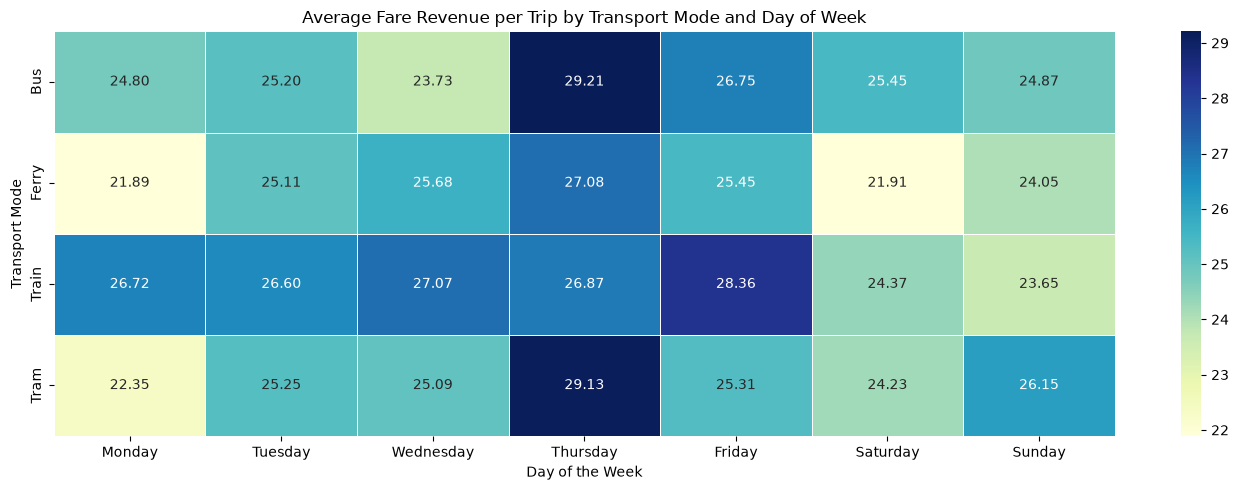

In [144]:
# Compare average fare revenue by transport mode and weekday

revenue_heatmap = df.pivot_table(
    index="Mode_of_Transport",
    columns="Day_of_Week",
    values="Fare_Amount",
    aggfunc="mean"
).reindex(columns=day_order)

fig, ax = plt.subplots(figsize=(14, 5))

sns.heatmap(
    revenue_heatmap,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    linewidths=0.5,
    ax=ax
)

ax.set_title("Average Fare Revenue per Trip by Transport Mode and Day of Week")
ax.set_xlabel("Day of the Week")
ax.set_ylabel("Transport Mode")

plt.tight_layout()
plt.show()

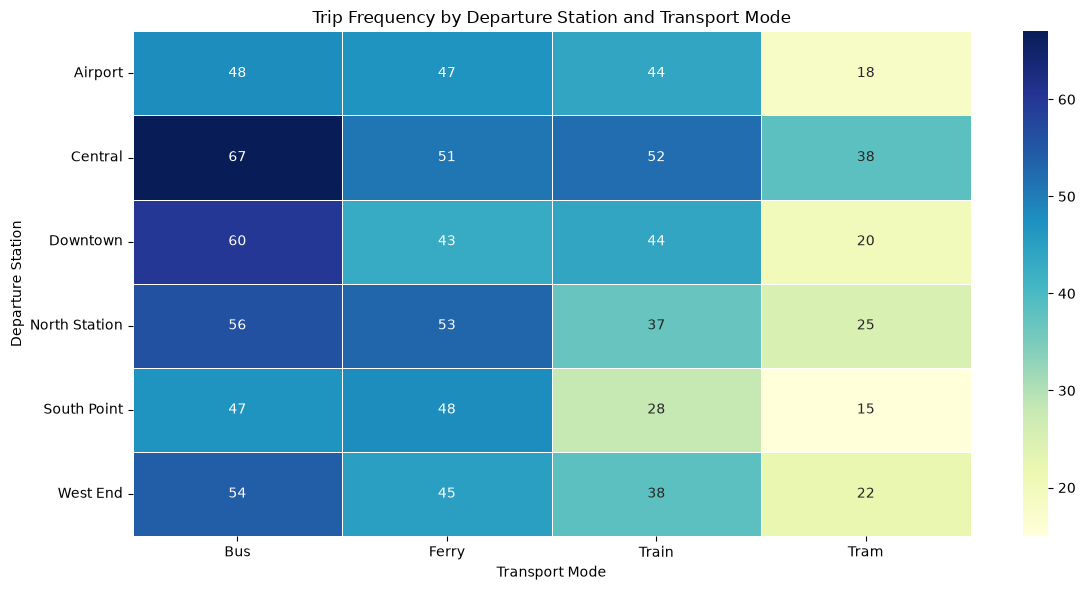

In [145]:
# Check trip frequency by departure station and transport mode
station_mode = pd.crosstab(
    df["Departure_Station"],
    df["Mode_of_Transport"]
)

fig, ax = plt.subplots(figsize=(12, 6))

sns.heatmap(
    station_mode,
    annot=True,
    fmt="d",
    cmap="YlGnBu",
    linewidths=0.5,
    ax=ax
)

ax.set_title("Trip Frequency by Departure Station and Transport Mode")
ax.set_xlabel("Transport Mode")
ax.set_ylabel("Departure Station")

plt.tight_layout()
plt.show()

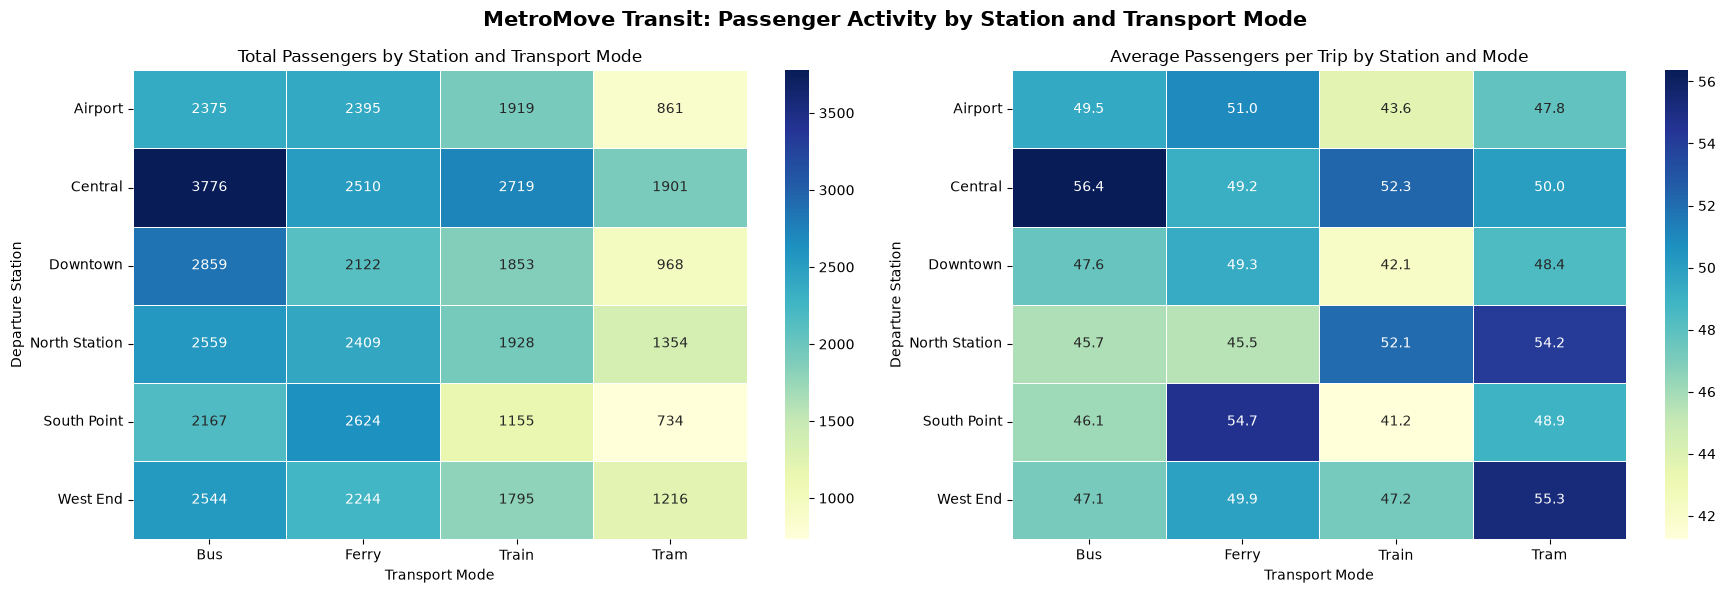

In [146]:
# Compare total and average passengers by departure station and transport mode

# Total passengers
station_passengers_total = df.pivot_table(
    index="Departure_Station",
    columns="Mode_of_Transport",
    values="Passenger_Count",
    aggfunc="sum"
)

# Average passengers per trip
station_passengers_avg = df.pivot_table(
    index="Departure_Station",
    columns="Mode_of_Transport",
    values="Passenger_Count",
    aggfunc="mean"
)

# Create two heatmaps
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Chart 1: Total passenger volume
sns.heatmap(
    station_passengers_total,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu",
    linewidths=0.5,
    ax=axes[0]
)

axes[0].set_title("Total Passengers by Station and Transport Mode")
axes[0].set_xlabel("Transport Mode")
axes[0].set_ylabel("Departure Station")

# Chart 2: Average passengers per trip
sns.heatmap(
    station_passengers_avg,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    linewidths=0.5,
    ax=axes[1]
)

axes[1].set_title("Average Passengers per Trip by Station and Mode")
axes[1].set_xlabel("Transport Mode")
axes[1].set_ylabel("Departure Station")

plt.suptitle(
    "MetroMove Transit: Passenger Activity by Station and Transport Mode",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

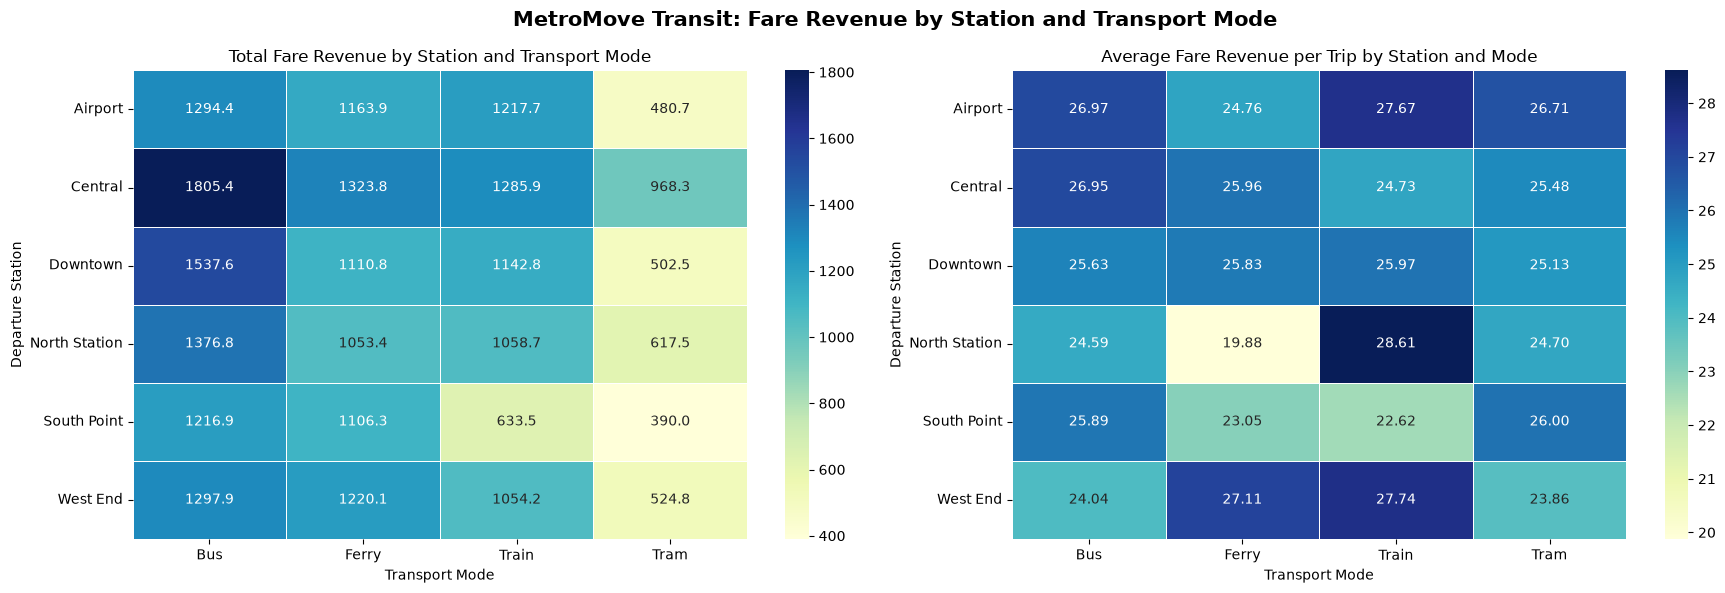

In [147]:
# Compare total and average fare revenue by departure station and transport mode

# Total fare revenue
station_revenue_total = df.pivot_table(
    index="Departure_Station",
    columns="Mode_of_Transport",
    values="Fare_Amount",
    aggfunc="sum"
)

# Average fare revenue per trip
station_revenue_avg = df.pivot_table(
    index="Departure_Station",
    columns="Mode_of_Transport",
    values="Fare_Amount",
    aggfunc="mean"
)

# Create two heatmaps
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

sns.heatmap(
    station_revenue_total,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    linewidths=0.5,
    ax=axes[0]
)

axes[0].set_title("Total Fare Revenue by Station and Transport Mode")
axes[0].set_xlabel("Transport Mode")
axes[0].set_ylabel("Departure Station")

sns.heatmap(
    station_revenue_avg,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    linewidths=0.5,
    ax=axes[1]
)

axes[1].set_title("Average Fare Revenue per Trip by Station and Mode")
axes[1].set_xlabel("Transport Mode")
axes[1].set_ylabel("Departure Station")

plt.suptitle(
    "MetroMove Transit: Fare Revenue by Station and Transport Mode",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

### Fare revenue per passenger

For each station–mode combination, I divide **total fare revenue by total passengers**. This is an aggregate revenue ratio, not a verified ticket price, profit margin or capacity measure. Both the numerator and denominator include imputed values.

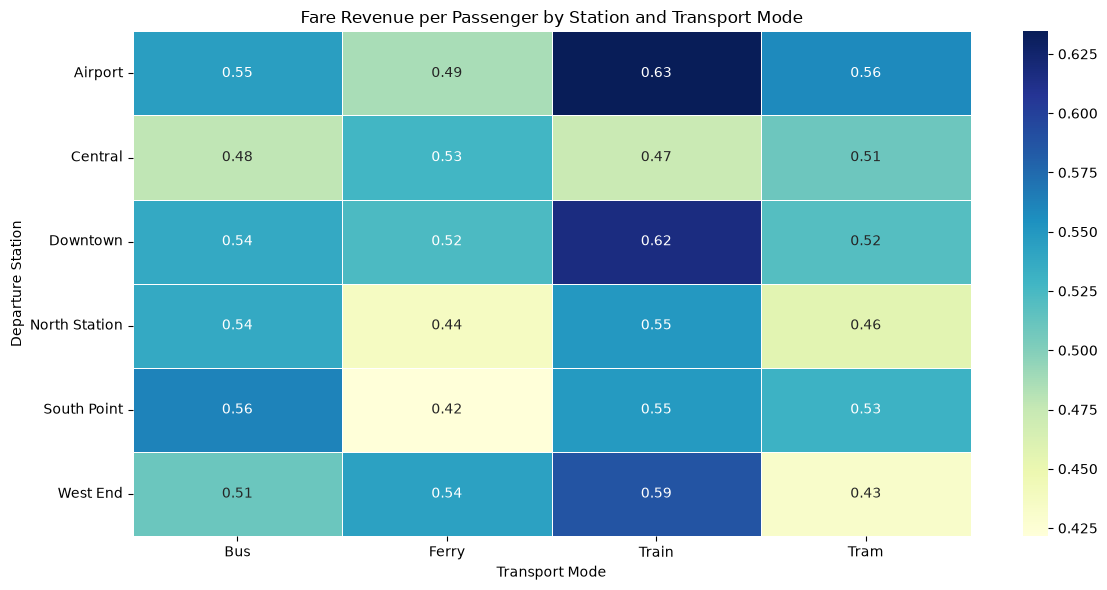

In [148]:
# Calculate revenue per passenger by transport mode and departure station
revenue_per_passenger = df.pivot_table(
    index="Departure_Station",
    columns="Mode_of_Transport",
    values=["Fare_Amount", "Passenger_Count"],
    aggfunc="sum"
)

# Divide total fare revenue by total passenger counts
revenue_efficiency = (
    revenue_per_passenger["Fare_Amount"] /
    revenue_per_passenger["Passenger_Count"]
)

# Plot revenue per passenger
fig, ax = plt.subplots(figsize=(12, 6))

sns.heatmap(
    revenue_efficiency,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    linewidths=0.5,
    ax=ax
)

ax.set_title("Fare Revenue per Passenger by Station and Transport Mode")
ax.set_xlabel("Transport Mode")
ax.set_ylabel("Departure Station")

plt.tight_layout()
plt.show()

### Final transport-mode summary

This table brings the main measures together in one place so I can compare trip frequency, passengers, fare revenue, duration and revenue per passenger without jumping between charts.

In [149]:
# Summarise key transport performance indicators by mode
mode_summary = df.groupby("Mode_of_Transport").agg(
    Total_Trips=("Trip_ID", "count"),
    Total_Passengers=("Passenger_Count", "sum"),
    Avg_Passengers=("Passenger_Count", "mean"),
    Total_Revenue=("Fare_Amount", "sum"),
    Avg_Revenue=("Fare_Amount", "mean"),
    Avg_Duration=("Trip_Duration_Minutes", "mean")
)

# Calculate revenue per passenger
mode_summary["Revenue_Per_Passenger"] = (
    mode_summary["Total_Revenue"] /
    mode_summary["Total_Passengers"]
)

mode_summary.round(2)

,Total_Trips,Total_Passengers,Avg_Passengers,Total_Revenue,Avg_Revenue,Avg_Duration,Revenue_Per_Passenger
Mode_of_Transport,,,,,,,
Bus,332,16280,49.04,8529.03,25.69,96.59,0.52
Ferry,287,14304,49.84,6978.38,24.31,91.72,0.49
Train,243,11369,46.79,6392.61,26.31,94.83,0.56
Tram,138,7034,50.97,3483.84,25.25,94.94,0.50


### How much data was estimated?

Each of the three numerical columns needed **100 replacements (10%)**, but they were not all missing on the same trips. The trip-level check below shows how many records had one, two or three estimated fields. This matters when I describe the reliability of the results.

In [150]:
# Review the number and percentage of imputed records by variable
imputation_summary = pd.DataFrame({
    "Variable": [
        "Passenger_Count",
        "Fare_Amount",
        "Trip_Duration_Minutes"
    ],
    "Imputed_Records": [
        df["Passenger_Count_Imputed"].sum(),
        df["Fare_Amount_Imputed"].sum(),
        df["Trip_Duration_Imputed"].sum()
    ]
})

imputation_summary["Imputed_Percent"] = (
    imputation_summary["Imputed_Records"] / len(df) * 100
)

imputation_summary

,Variable,Imputed_Records,Imputed_Percent
0,Passenger_Count,100,10.0
1,Fare_Amount,100,10.0
2,Trip_Duration_Minutes,100,10.0


In [151]:
# Check how many numerical variables were imputed in each trip
imputation_cols = [
    "Passenger_Count_Imputed",
    "Fare_Amount_Imputed",
    "Trip_Duration_Imputed"
]

# Count the number of imputed fields per trip
df["Imputed_Fields_Count"] = df[imputation_cols].sum(axis=1)

# Show the distribution
df["Imputed_Fields_Count"].value_counts().sort_index()

Imputed_Fields_Count
0    733
1    236
2     29
3      2
Name: count, dtype: int64

## 7. Findings, limitations and recommendations

### 7.1 What I changed during cleaning

I started with **1,000 trip records** and checked missing values, duplicates, category labels and dates before building the main charts.

The most serious issue was the time information. All `Departure_Time` values were attached to **1 January 2024**, and each consecutive timestamp was exactly **one minute** after the previous one. Only **24 records** had a departure date matching `Trip_Date`; the other **976 did not**. Meanwhile, `Trip_Date` covered **42 days (1 January to 11 February 2024)**, with exactly **24 records on most days** and **16 on the final day**. Those patterns look mechanically generated, so I have not treated the recorded clock times as evidence of real peak hours.

The original weekday labels also disagreed with the dates in **850 of 1,000 rows**. I recalculated `Day_of_Week` from `Trip_Date`, but that remains a **provisional correction** because the dates themselves have not been independently verified.

I standardised transport modes and station names so differences in case and spacing no longer split the same category. I removed two unexplained unnamed columns, as well as temporary comparison fields and the inconsistent duplicate weekday column.

For the numerical fields, I used the median **within each transport mode** to fill missing entries and kept flags marking the replacements:

| Field | Estimated values | Share of trips |
|---|---:|---:|
| `Passenger_Count` | 100 | 10.0% |
| `Fare_Amount` | 100 | 10.0% |
| `Trip_Duration_Minutes` | 100 | 10.0% |

The trip-level check shows **733 trips (73.3%)** with none of these three fields imputed, **236** with one imputed field, **29** with two and **2** with all three. In total, **267 trips (26.7%)** contain at least one estimated numerical value. I retained these trips for the cleaned-data analysis but have not treated the estimates as observed collections or headcounts.

**What I would improve:** Capture valid dates and times at source, enforce standard station and mode labels, record why a value is missing, and recover missing fares or passenger counts from the operational system where possible.

### 7.2 Transport modes: volume and typical trips

| Measure | Highest mode | Result |
|---|---|---:|
| Recorded trips | Bus | 332 |
| Total passengers | Bus | 16,280 |
| Average passengers per trip | Tram | 50.97 |
| Total fare revenue | Bus | 8,529.03 |
| Average fare revenue per trip | Train | 26.31 |
| Aggregate revenue per passenger | Train | 0.56 |
| Shortest average duration | Ferry | 91.72 minutes |

Bus accounts for the largest share of trips (**33.2%**) and leads in total passengers and fare revenue. Tram operates the fewest recorded trips (**138**) but has the highest average passenger count per trip. Train produces the highest average revenue per trip and revenue per passenger.

The main lesson is that **high totals and high per-trip averages are not the same thing**. A mode can lead in totals partly because it has more recorded trips. I would compare both before making scheduling decisions, then add vehicle capacity, operating cost and actual load factors before drawing any conclusions about efficiency or profitability.

### 7.3 Stations and directional trip flow

**Central** has the most departures (**208**), the highest departing passenger total (**10,906**) and the most departure-based fare revenue (about **5,383.4**). **Airport** receives the most arrivals (**213**).

I calculated the net number of recorded trips as **arrivals − departures**:

| Station | Net trips |
|---|---:|
| Airport | +56 |
| South Point | +33 |
| West End | +4 |
| Downtown | +1 |
| North Station | −46 |
| Central | −48 |

Airport and South Point receive more trips than they originate, while Central and North Station have the opposite pattern. This is worth checking against service schedules, but it **doesn't prove** a vehicle shortage or a net flow of passengers. I would validate the directions and service coverage before suggesting rebalancing.

At the station-and-mode level, **Central Bus** records **3,776 passengers** and around **1,805.4** in total fare revenue. **North Station Train** has a relatively high average revenue per trip (**28.61**). Again, total activity and the average for a typical trip give different pictures.

### 7.4 Routes and same-station trips

The most frequent directional route is **North Station → Airport (44 trips)**. It also carries the most passengers in the route ranking (**2,149**). **Central → Airport** has the highest route-level total fare revenue (about **1,135.5**), even though its passenger total is lower (**2,023**).

One issue I did not want to overlook is the **164 trips (16.4%)** where the departure and arrival stations match. For example, there are **37 Airport → Airport** and **32 Central → Central** records. Same-station trips average **99.28 minutes**, compared with **93.60 minutes** for different-station trips. They also have slightly lower average passengers and revenue. The gaps differ by transport mode, with a particularly large duration difference for Tram.

These might be circular services, but I cannot confirm that from this file. I kept the records and flagged them as a question for MetroMove's route or operations team. I would not remove 16.4% of the dataset based on the station names alone.

I also found no consistent rule that longer routes collect more fare revenue. Route distance, fare rules and ticket details would be needed to investigate that properly.

### 7.5 Daily trends and revenue relationships

Daily passenger totals and fare revenue fluctuate without a clear sustained trend. Both fall on **11 February**, the partial final day. I checked per-trip daily averages as well, because comparing totals alone gives days with more recorded trips an advantage. Even those averages dip on the final date, but with only 16 records I would not label it a demand collapse.

At the **individual-trip level**, the cleaned-data Pearson correlations are close to zero:

| Pair of variables | Correlation |
|---|---:|
| Passengers and fare revenue | 0.013 |
| Passengers and duration | 0.019 |
| Fare revenue and duration | −0.041 |

Using only trips with all three original numerical values gives similarly small correlations (**0.010**, **0.012** and **−0.055**, respectively). This suggests the median replacements did not substantially alter these particular linear relationships.

At the **daily-average level**, the correlation between average passengers per trip and average fare revenue per trip is **0.256**: a weak positive relationship, not a strong one. I wouldn't infer causation from either the trip-level or daily-level charts.

It is also worth checking how `Fare_Amount` was recorded. The assignment treats it as the total collected per trip, but the observed data shows little relationship with passenger count. Fare rules, discounts, tickets and payment records would help explain whether that pattern is expected.

### 7.6 Comparisons involving mode, weekday and route type

The weekday heatmaps show differences across modes. For example, **Bus** has its highest average passengers and revenue per trip on **Thursday** (**57.0 passengers** and **29.21**). **Tram** has its highest average passengers on **Friday** (**57.0**), but highest average revenue on **Thursday** (**29.13**). So days with more passengers do not always have the largest average collections.

The trip-duration charts also show that the difference between same-station and different-station trips is not uniform across transport modes. I see these as leads for further investigation, not established explanations of operations.

Because weekdays come from the provisional dates, I would **not** use these charts alone to set an actual weekly timetable.

### 7.7 Limits I would state alongside the results

- **Dates and times:** The fixed departure date, minute-by-minute timestamps and repeated daily record counts suggest a generated or unreliable schedule. Peak-hour and weekday claims need validation.
- **Estimated values:** At least one numerical field was imputed in 26.7% of trips. Totals and averages are based partly on estimates.
- **Same-station routes:** I cannot tell whether the 164 same-station records are circular services or data errors without route definitions.
- **Missing operating context:** The file does not provide distances, vehicle capacities, delays, ticket rules or operating costs. It cannot establish profitability, occupancy or journey efficiency.
- **Correlation is limited:** The near-zero Pearson coefficients describe linear association, not every possible relationship or a causal effect.

### 7.8 Recommendations and conclusion

My first recommendation is to **fix the source data before using this dataset for operational decisions**. I would prioritise reliable timestamps and trip dates, clear route definitions, consistent station labels and auditable passenger and fare records.

For reporting, I would show **trip counts, total passengers, average passengers per trip, total fare revenue and average revenue per trip together**. This avoids assuming that a busy mode or station is automatically the most efficient. I would also monitor departure/arrival differences and same-station journeys, then verify them with route schedules rather than treating them as errors straight away.

Overall, the EDA gives a useful picture of the **recorded** MetroMove activity. Bus leads in total trips, passengers and fare revenue; Tram has the highest average passengers per trip; and Train has the highest average fare revenue per trip and aggregate revenue per passenger. Central stands out for departures, while Airport stands out for arrivals.

The stronger finding, though, is about **data reliability**. Several of the patterns look too regular to treat as verified operational behaviour. The analysis is useful for highlighting questions MetroMove should investigate, but I'd validate the underlying records before using the results to change services or pricing.